# Онлайн магазин за техника - анализ на продажби, клиенти и мнения

Курсов проект по "Големи данни"

## Етап 1. Подготовка и зареждане на данните

### 1.1. Библиотеки и начално състояние

In [1]:
import os
from datetime import date
import re
import json
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from faker import Faker
from scipy.stats import zscore, norm, uniform, binom, pearsonr, spearmanr
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS

Faker.seed(42)
np.random.seed(42)

fake = Faker("bg_BG")

# общ стил и размер на всички графики
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

### 1.2. Клиенти

In [2]:
cities = ["София", "Пловдив", "Варна", "Бургас", "Русе", "Стара Загора", "Плевен"]
city_share = [0.36, 0.17, 0.15, 0.11, 0.08, 0.07, 0.06]

customer_categories = ["Редовен", "Лоялен", "VIP"]
customer_category_share = [0.70, 0.22, 0.08]

In [3]:
# датите са фиксирани, за да се получават едни и същи данни при всяко пускане
customers_data = []
for i in range(1, 2001):
    customers_data.append({
        "CustomerID": f"C{i:04d}",
        "Name": fake.name(),
        "Age": fake.random_int(min=18, max=70),
        "City": np.random.choice(cities, p=city_share),
        "RegistrationDate": fake.date_between(
            start_date=date(2023, 1, 1),
            end_date=date(2026, 9, 30)
        ),
        "CustomerCategory": np.random.choice(customer_categories, p=customer_category_share)
    })

customers = pd.DataFrame(customers_data)
customers["RegistrationDate"] = pd.to_datetime(customers["RegistrationDate"])
print(customers.head())

  CustomerID                Name  Age     City RegistrationDate  \
0      C0001    Аделин Топчийски   35  Пловдив       2024-01-16   
1      C0002  Г-н Тонко Количков   61   Бургас       2026-02-24   
2      C0003       Пенчин Канчин   20    София       2023-02-16   
3      C0004          Едвин Яков   50    София       2025-07-24   
4      C0005     Панталей Дзезов   63    Варна       2025-10-06   

  CustomerCategory  
0              VIP  
1          Редовен  
2          Редовен  
3           Лоялен  
4           Лоялен  


### 1.3. Продукти

In [4]:
products = pd.DataFrame([
    ["Лаптоп", "Компютри", 1899, 1650],
    ["Настолен компютър", "Компютри", 1599, 1390],
    ["Монитор", "Компютри", 389, 305],
    ["Принтер", "Компютри", 259, 200],
    ["Клавиатура", "Компютри", 69, 38],
    ["Мишка", "Компютри", 39, 19],
    ["Смартфон", "Телефони и таблети", 1199, 1040],
    ["Таблет", "Телефони и таблети", 649, 545],
    ["Смарт часовник", "Телефони и таблети", 399, 300],
    ["Безжични слушалки", "Телефони и таблети", 149, 85],
    ["Зарядно устройство", "Телефони и таблети", 35, 14],
    ["Телевизор", "Телевизори и аудио", 1299, 1090],
    ["Саундбар", "Телевизори и аудио", 349, 250],
    ["Преносима колонка", "Телевизори и аудио", 119, 70],
    ["Хладилник", "Голяма домакинска техника", 1099, 900],
    ["Пералня", "Голяма домакинска техника", 849, 690],
    ["Съдомиялна", "Голяма домакинска техника", 899, 735],
    ["Готварска печка", "Голяма домакинска техника", 749, 610],
    ["Климатик", "Голяма домакинска техника", 1249, 1000],
    ["Робот прахосмукачка", "Малки домакински уреди", 599, 430],
    ["Прахосмукачка", "Малки домакински уреди", 229, 150],
    ["Кафемашина", "Малки домакински уреди", 329, 205],
    ["Микровълнова фурна", "Малки домакински уреди", 189, 125],
    ["Конвектор", "Малки домакински уреди", 129, 80],
    ["Блендер", "Малки домакински уреди", 89, 48],
    ["Ютия", "Малки домакински уреди", 79, 44],
    ["Електрическа кана", "Малки домакински уреди", 49, 24]
], columns=["Product", "Category", "UnitPrice", "Cost"])

product_ids = []
for i in range(1, len(products) + 1):
    product_ids.append(f"P{i:02d}")

products.insert(0, "ProductID", product_ids)

print(products)

   ProductID              Product                   Category  UnitPrice  Cost
0        P01               Лаптоп                   Компютри       1899  1650
1        P02    Настолен компютър                   Компютри       1599  1390
2        P03              Монитор                   Компютри        389   305
3        P04              Принтер                   Компютри        259   200
4        P05           Клавиатура                   Компютри         69    38
5        P06                Мишка                   Компютри         39    19
6        P07             Смартфон         Телефони и таблети       1199  1040
7        P08               Таблет         Телефони и таблети        649   545
8        P09       Смарт часовник         Телефони и таблети        399   300
9        P10    Безжични слушалки         Телефони и таблети        149    85
10       P11   Зарядно устройство         Телефони и таблети         35    14
11       P12            Телевизор         Телевизори и аудио    

### 1.4. Поръчки и детайли на поръчките

Броят поръчки на ден зависи от деня от седмицата, от сезона и от постепенния ръст на магазина.

#### Период и настройки

In [5]:
days = pd.date_range(start="2025-11-01", end="2026-10-31", freq="D")
weekday_factor = [0.80, 0.75, 0.80, 0.95, 1.20, 1.50, 1.40]

black_friday_start = pd.Timestamp("2025-11-24")
black_friday_end = pd.Timestamp("2025-11-30")
defect_start = pd.Timestamp("2026-06-01")

payments = ["Карта", "Наложен платеж", "Банков превод"]
payment_share = [0.55, 0.35, 0.10]

#### Популярност на продуктите и активност на клиентите

In [6]:
robot = products["Product"] == "Робот прахосмукачка"
air_conditioner = products["Product"] == "Климатик"
convector = products["Product"] == "Конвектор"

# по-скъпите продукти се купуват по-рядко, а роботът прахосмукачка е хит
popularity = 1 / np.sqrt(products["UnitPrice"])
popularity[robot] = popularity[robot] * 3

# VIP и лоялните клиенти поръчват по-често
customer_weight = customers["CustomerCategory"].map({"Редовен": 1, "Лоялен": 3, "VIP": 6})

#### Брой поръчки за деня

In [7]:
def orders_for_day(day_index, current_day):
    expected_orders = 36 * (1 + 0.5 * day_index / 365) * weekday_factor[current_day.day_of_week]

    if black_friday_start <= current_day <= black_friday_end:
        expected_orders = expected_orders * 2.5
    elif current_day.month == 12 and current_day.day <= 23:
        expected_orders = expected_orders * 1.4
    elif current_day.month == 1:
        expected_orders = expected_orders * 0.75

    return np.random.poisson(expected_orders)

#### Сезонно търсене на продуктите

In [8]:
# климатиците се търсят през лятото, конвекторите през зимата
def product_weights(current_day):
    weights = popularity.copy()
    if current_day.month in [6, 7, 8]:
        weights[air_conditioner] = weights[air_conditioner] * 3
    if current_day.month in [11, 12, 1, 2]:
        weights[convector] = weights[convector] * 4
    return weights

#### Статус на поръчката

In [9]:
# при наложен платеж отказите са повече, а дефектният продукт се връща често
def choose_status(payment_method, has_defective_product):
    cancel_chance = 0.03
    if payment_method == "Наложен платеж":
        cancel_chance = 0.18

    return_chance = 0.015
    if has_defective_product:
        return_chance = 0.35

    if np.random.random() < cancel_chance:
        return "Отказана"
    if np.random.random() < return_chance:
        return "Върната"
    return "Доставена"

#### Генериране на поръчките

In [10]:
orders_data = []
items_data = []
order_id = 10001

for day_number, day in enumerate(days):
    black_friday = black_friday_start <= day <= black_friday_end
    weights = product_weights(day)

    # поръчват само вече регистрираните клиенти
    registered = customers["RegistrationDate"] <= day
    customer_ids = customers.loc[registered, "CustomerID"]
    customer_share = customer_weight[registered] / customer_weight[registered].sum()

    for _ in range(orders_for_day(day_number, day)):
        customer_id = np.random.choice(customer_ids, p=customer_share)
        payment = np.random.choice(payments, p=payment_share)

        n_items = np.random.choice([1, 2, 3], p=[0.60, 0.30, 0.10])
        chosen = products.sample(n_items, weights=weights)

        # дефектна партида на робота прахосмукачка от 1 юни 2026
        defective = day >= defect_start and "Робот прахосмукачка" in chosen["Product"].values
        status = choose_status(payment, defective)

        for _, product in chosen.iterrows():
            price = product["UnitPrice"]

            # скъпите продукти се купуват по един брой
            quantity = 1
            if price < 200:
                quantity = np.random.choice([1, 2, 3], p=[0.45, 0.35, 0.20])

            if black_friday:
                price = round(price * 0.85, 2)

            items_data.append({
                "OrderID": order_id,
                "ProductID": product["ProductID"],
                "Quantity": quantity,
                "UnitPrice": price,
                "LineTotal": round(quantity * price, 2)
            })

        orders_data.append({
            "OrderID": order_id,
            "CustomerID": customer_id,
            "Date": day,
            "Status": status,
            "PaymentMethod": payment
        })
        order_id += 1

In [11]:
orders = pd.DataFrame(orders_data)
order_items = pd.DataFrame(items_data)

print(orders.head())
print(order_items.head())

   OrderID CustomerID       Date     Status   PaymentMethod
0    10001      C1501 2025-11-01  Доставена           Карта
1    10002      C0119 2025-11-01  Доставена           Карта
2    10003      C1774 2025-11-01  Доставена  Наложен платеж
3    10004      C1339 2025-11-01   Отказана  Наложен платеж
4    10005      C0698 2025-11-01  Доставена  Наложен платеж
   OrderID ProductID  Quantity  UnitPrice  LineTotal
0    10001       P10         2      149.0      298.0
1    10002       P24         1      129.0      129.0
2    10003       P08         1      649.0      649.0
3    10004       P24         2      129.0      258.0
4    10004       P13         1      349.0      349.0


### 1.5. Клиентски мнения

Приемам, че магазинът събира мненията на английски през платформа за оценки. Така могат да се анализират с VADER и stop words от упражненията, които работят с английски текст.

#### Изречения за мненията

In [12]:
positive_start = [
    "I love this product.", "Great purchase.", "Excellent quality.", "Very happy with my order.",
    "Amazing value for the price.", "Perfect, exactly what I wanted.", "Really good product.",
    "I am very satisfied.", "Awesome store.", "Best purchase this year."
]
positive_middle = [
    "Fast delivery and great price.", "It works perfectly and looks nice.", "Easy to use and very quiet.",
    "The customer service was friendly and helpful.", "Good quality and fast delivery.",
    "It arrived on time and well packed.", "Great price and excellent quality.",
    "Super easy to set up.", "The courier was kind and the delivery was fast.", "Better than I expected."
]
positive_end = [
    "Highly recommended.", "I will definitely order again.", "Thank you.", "Five stars from me.",
    "My family is happy too.", "I already recommended the store to a friend.", "Good job.",
    "Worth every penny.", "Will buy again.", "Totally worth it."
]

neutral_start = [
    "The product arrived on Monday.", "It does what the description says.", "The order was delivered to the office.",
    "I ordered it for my parents.", "The package came with a manual.", "It is an average product.",
    "Delivery took three days.", "I have used it for one week.", "The box was a bit big.", "Standard product."
]
neutral_middle = [
    "The price is average.", "The colour is a bit different.", "I expected a longer cable.",
    "It is the second one I buy.", "The courier called in advance.", "Used it only twice so far.",
    "The manual is only in English.", "It is heavier than the old one.", "The size is as described.",
    "It has two modes."
]
neutral_end = [
    "Nothing more to add.", "Time will tell.", "That is all for now.", "We will see how long it lasts.",
    "Maybe I will update the review later.", "No other comments.", "It is what it is.",
    "I have no opinion yet.", "Normal order.", "Nothing unusual."
]

negative_start = [
    "Very disappointed.", "Poor quality.", "Not happy with this order.", "Bad experience.",
    "Terrible product.", "I regret buying it.", "Waste of money.", "Not what I expected, sadly.",
    "Awful.", "Horrible purchase."
]
negative_middle = [
    "The product arrived damaged.", "It broke after a few days.", "The customer service ignored my problem.",
    "It is too noisy and feels cheap.", "The quality is worse than expected.", "I had to pay for the return myself.",
    "The buttons stopped working.", "The box was damaged and a part was missing.",
    "It looks used and scratched.", "It failed after the first week."
]
negative_end = [
    "I want my money back.", "Never again.", "I do not recommend it.", "Very annoying.",
    "I will not order again.", "Avoid it.", "One star.", "Total disappointment.",
    "I am angry.", "Bad service."
]

#### Изречения за дефектния продукт и за закъснелите доставки

In [13]:
defect_middle = [
    "The robot vacuum stopped charging after two weeks.", "The battery died after ten days.",
    "The robot vacuum stopped working and I returned it.", "The battery died again, the second unit is also defective.",
    "It stopped charging and the support was useless.", "Defective battery, the robot vacuum is useless now.",
    "The robot vacuum stopped working after one month.", "The battery died and the robot vacuum does not start."
]
late_middle = [
    "Late delivery, it arrived after the holidays.", "The late delivery ruined my Christmas gift.",
    "Terrible delay, late delivery again.", "Late delivery and nobody answered the phone.",
    "Two weeks of waiting, very late delivery.", "The late delivery was a big problem for me."
]

#### Съставяне на едно мнение

In [14]:
def make_review(sentiment, middle):
    if sentiment == "Positive":
        start = np.random.choice(positive_start)
        end = np.random.choice(positive_end)
        rating = np.random.choice([4, 5], p=[0.3, 0.7])
    elif sentiment == "Neutral":
        start = np.random.choice(neutral_start)
        end = np.random.choice(neutral_end)
        rating = 3
    else:
        start = np.random.choice(negative_start)
        end = np.random.choice(negative_end)
        rating = np.random.choice([1, 2], p=[0.6, 0.4])
    return f"{start} {np.random.choice(middle)} {end}", rating

#### Шум в текста

In [15]:
# линкове, споменавания, хаштагове и главни букви, както в реалните мнения
def add_noise(text):
    noise = np.random.random()
    if noise < 0.08:
        text = text + " More photos at https://example.com/reviews"
    elif noise < 0.16:
        text = "@techstore " + text
    elif noise < 0.24:
        text = text + " #onlineshop"
    elif noise < 0.30:
        text = text.upper()
    return text

#### Закупени продукти

Мнение може да се напише само за продукт от поръчка, която не е отказана.

In [16]:
received_orders = orders[orders["Status"] != "Отказана"]
purchases = order_items.merge(received_orders, on="OrderID")
purchases = purchases.merge(products[["ProductID", "Product"]], on="ProductID")
print(purchases.head())

   OrderID ProductID  Quantity  UnitPrice  LineTotal CustomerID       Date  \
0    10001       P10         2      149.0      298.0      C1501 2025-11-01   
1    10002       P24         1      129.0      129.0      C0119 2025-11-01   
2    10003       P08         1      649.0      649.0      C1774 2025-11-01   
3    10005       P05         3       69.0      207.0      C0698 2025-11-01   
4    10006       P20         1      599.0      599.0      C1949 2025-11-01   

      Status   PaymentMethod              Product  
0  Доставена           Карта    Безжични слушалки  
1  Доставена           Карта            Конвектор  
2  Доставена  Наложен платеж               Таблет  
3  Доставена  Наложен платеж           Клавиатура  
4  Доставена  Наложен платеж  Робот прахосмукачка  


#### Генериране на мненията

In [17]:
sentiments = ["Positive", "Neutral", "Negative"]
middles = {"Positive": positive_middle, "Neutral": neutral_middle, "Negative": negative_middle}

reviews_data = []
review_id = 1

for _, row in purchases.iterrows():
    defective = row["Product"] == "Робот прахосмукачка" and row["Date"] >= defect_start
    before_christmas = row["Date"].month == 12 and row["Date"].day <= 23

    # недоволните клиенти пишат мнение по-често
    review_chance = 0.05
    if defective:
        review_chance = 0.40

    if np.random.random() < review_chance:
        if defective and np.random.random() < 0.85:
            text, rating = make_review("Negative", defect_middle)
        elif before_christmas and np.random.random() < 0.45:
            text, rating = make_review("Negative", late_middle)
        else:
            sentiment = np.random.choice(sentiments, p=[0.72, 0.18, 0.10])
            text, rating = make_review(sentiment, middles[sentiment])

        reviews_data.append({
            "ReviewID": review_id,
            "OrderID": row["OrderID"],
            "CustomerID": row["CustomerID"],
            "ProductID": row["ProductID"],
            "ReviewDate": row["Date"] + pd.Timedelta(days=np.random.randint(2, 8)),
            "ReviewText": add_noise(text),
            "Rating": rating
        })
        review_id += 1

reviews = pd.DataFrame(reviews_data)
print(reviews.head())

   ReviewID  OrderID CustomerID ProductID ReviewDate  \
0         1    10069      C0945       P13 2025-11-05   
1         2    10101      C0651       P25 2025-11-05   
2         3    10102      C0925       P27 2025-11-04   
3         4    10118      C0938       P05 2025-11-05   
4         5    10120      C0751       P11 2025-11-09   

                                          ReviewText  Rating  
0  I am very satisfied. The customer service was ...       5  
1  @techstore Great purchase. Easy to use and ver...       4  
2  @techstore Very happy with my order. Easy to u...       5  
3  Really good product. Better than I expected. T...       5  
4  I love this product. Super easy to set up. Goo...       5  


### 1.6. Контролирани проблеми в данните

Нарочно добавям проблеми в данните, за да ги обработя в Етап 2.

#### Липсващи стойности

In [18]:
customers.loc[customers.sample(100, random_state=42).index, "Age"] = np.nan
orders.loc[orders.sample(180, random_state=42).index, "PaymentMethod"] = np.nan
reviews.loc[reviews.sample(15, random_state=42).index, "ReviewText"] = np.nan

#### Различно изписване на градовете

In [19]:
city_rows = customers.sample(160, random_state=1).index
upper_rows = city_rows[:80]
lower_rows = city_rows[80:]

customers.loc[upper_rows, "City"] = customers.loc[upper_rows, "City"].str.upper()
customers.loc[lower_rows, "City"] = " " + customers.loc[lower_rows, "City"].str.lower() + " "

#### Отклоняващи се количества

In [20]:
# грешки при въвеждане на количеството при евтини продукти
outlier_rows = order_items[order_items["UnitPrice"] < 200].sample(40, random_state=42).index

order_items.loc[outlier_rows, "Quantity"] = np.random.randint(20, 60, size=40)
order_items.loc[outlier_rows, "LineTotal"] = (
    order_items.loc[outlier_rows, "Quantity"] * order_items.loc[outlier_rows, "UnitPrice"]
).round(2)

#### Дублирани записи

In [21]:
customers = pd.concat([customers, customers.sample(40, random_state=7)], ignore_index=True)
orders = pd.concat([orders, orders.sample(90, random_state=7)], ignore_index=True)
reviews = pd.concat([reviews, reviews.sample(25, random_state=7)], ignore_index=True)

### 1.7. Записване в CSV файлове

In [22]:
customers.to_csv("data/customers.csv", index=False)
products.to_csv("data/products.csv", index=False)
orders.to_csv("data/orders.csv", index=False)
order_items.to_csv("data/order_items.csv", index=False)
reviews.to_csv("data/reviews.csv", index=False)

print("Клиенти:", customers.shape)
print("Продукти:", products.shape)
print("Поръчки:", orders.shape)
print("Детайли на поръчките:", order_items.shape)
print("Мнения:", reviews.shape)

Клиенти: (2040, 6)
Продукти: (27, 5)
Поръчки: (18088, 5)
Детайли на поръчките: (26998, 5)
Мнения: (1475, 7)


### 1.8. Зареждане на CSV файловете

In [23]:
customers = pd.read_csv("data/customers.csv")
products = pd.read_csv("data/products.csv")
orders = pd.read_csv("data/orders.csv")
order_items = pd.read_csv("data/order_items.csv")
reviews = pd.read_csv("data/reviews.csv")

### 1.9. Размери на таблиците

In [24]:
tables = {
    "Клиенти": customers,
    "Продукти": products,
    "Поръчки": orders,
    "Детайли на поръчките": order_items,
    "Мнения": reviews
}

for name, table in tables.items():
    rows, columns = table.shape
    print(name, "- редове:", rows, "колони:", columns)

Клиенти - редове: 2040 колони: 6
Продукти - редове: 27 колони: 5
Поръчки - редове: 18088 колони: 5
Детайли на поръчките - редове: 26998 колони: 5
Мнения - редове: 1475 колони: 7


### 1.10. Структура и типове

След зареждането от CSV датите са текст. Това ще се коригира в Етап 2.

In [25]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 2040 entries, 0 to 2039
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        2040 non-null   str    
 1   Name              2040 non-null   str    
 2   Age               1938 non-null   float64
 3   City              2040 non-null   str    
 4   RegistrationDate  2040 non-null   str    
 5   CustomerCategory  2040 non-null   str    
dtypes: float64(1), str(5)
memory usage: 240.9 KB


In [26]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   ProductID  27 non-null     str  
 1   Product    27 non-null     str  
 2   Category   27 non-null     str  
 3   UnitPrice  27 non-null     int64
 4   Cost       27 non-null     int64
dtypes: int64(2), str(3)
memory usage: 2.8 KB


In [27]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 18088 entries, 0 to 18087
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   OrderID        18088 non-null  int64
 1   CustomerID     18088 non-null  str  
 2   Date           18088 non-null  str  
 3   Status         18088 non-null  str  
 4   PaymentMethod  17907 non-null  str  
dtypes: int64(1), str(4)
memory usage: 1.6 MB


In [28]:
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 26998 entries, 0 to 26997
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   OrderID    26998 non-null  int64  
 1   ProductID  26998 non-null  str    
 2   Quantity   26998 non-null  int64  
 3   UnitPrice  26998 non-null  float64
 4   LineTotal  26998 non-null  float64
dtypes: float64(2), int64(2), str(1)
memory usage: 1.1 MB


In [29]:
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 1475 entries, 0 to 1474
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   ReviewID    1475 non-null   int64
 1   OrderID     1475 non-null   int64
 2   CustomerID  1475 non-null   str  
 3   ProductID   1475 non-null   str  
 4   ReviewDate  1475 non-null   str  
 5   ReviewText  1460 non-null   str  
 6   Rating      1475 non-null   int64
dtypes: int64(3), str(4)
memory usage: 224.7 KB


### 1.11. Основни показатели

In [30]:
print(customers["Age"].describe())
print(reviews["Rating"].describe())

count    1938.000000
mean       44.447884
std        15.016034
min        18.000000
25%        31.250000
50%        44.000000
75%        58.000000
max        70.000000
Name: Age, dtype: float64
count    1475.000000
mean        3.521356
std         1.476197
min         1.000000
25%         2.000000
50%         4.000000
75%         5.000000
max         5.000000
Name: Rating, dtype: float64


In [31]:
print(products[["UnitPrice", "Cost"]].describe())

         UnitPrice         Cost
count    27.000000    27.000000
mean    555.148148   445.814815
std     532.684616   465.311892
min      35.000000    14.000000
25%     124.000000    75.000000
50%     349.000000   250.000000
75%     874.000000   712.500000
max    1899.000000  1650.000000


In [32]:
print(order_items[["Quantity", "UnitPrice", "LineTotal"]].describe())

           Quantity     UnitPrice     LineTotal
count  26998.000000  26998.000000  26998.000000
mean       1.504482    323.079895    365.753458
std        1.621189    398.894274    410.091101
min        1.000000     29.750000     29.750000
25%        1.000000     69.000000     98.000000
50%        1.000000    129.000000    229.000000
75%        2.000000    399.000000    399.000000
max       57.000000   1899.000000   9639.000000


#### Категориални колони

In [33]:
print(products["Category"].value_counts())
print(orders["Status"].value_counts())
print(orders["PaymentMethod"].value_counts())

Category
Малки домакински уреди       8
Компютри                     6
Телефони и таблети           5
Голяма домакинска техника    5
Телевизори и аудио           3
Name: count, dtype: int64
Status
Доставена    16112
Отказана      1501
Върната        475
Name: count, dtype: int64
PaymentMethod
Карта             9893
Наложен платеж    6283
Банков превод     1731
Name: count, dtype: int64


### 1.12. Връзки между таблиците

Проверявам дали всяка поръчка е на съществуващ клиент и дали всеки продаден продукт е в каталога.

In [34]:
print("Поръчки на несъществуващ клиент:", (~orders["CustomerID"].isin(customers["CustomerID"])).sum())
print("Редове с несъществуваща поръчка:", (~order_items["OrderID"].isin(orders["OrderID"])).sum())
print("Редове с несъществуващ продукт:", (~order_items["ProductID"].isin(products["ProductID"])).sum())
print("Мнения за несъществуваща поръчка:", (~reviews["OrderID"].isin(orders["OrderID"])).sum())

Поръчки на несъществуващ клиент: 0
Редове с несъществуваща поръчка: 0
Редове с несъществуващ продукт: 0
Мнения за несъществуваща поръчка: 0


#### Стойност на реда

In [35]:
calculated = (order_items["Quantity"] * order_items["UnitPrice"]).round(2)
print("Редове с грешна стойност:", (calculated != order_items["LineTotal"]).sum())

Редове с грешна стойност: 0


#### Свързване на детайлите с продуктите

In [36]:
items_products = order_items.merge(products[["ProductID", "Product", "Category"]], on="ProductID")
print(items_products.head())

   OrderID ProductID  Quantity  UnitPrice  LineTotal            Product  \
0    10001       P10         2      149.0      298.0  Безжични слушалки   
1    10002       P24         1      129.0      129.0          Конвектор   
2    10003       P08         1      649.0      649.0             Таблет   
3    10004       P24         2      129.0      258.0          Конвектор   
4    10004       P13         1      349.0      349.0           Саундбар   

                 Category  
0      Телефони и таблети  
1  Малки домакински уреди  
2      Телефони и таблети  
3  Малки домакински уреди  
4      Телевизори и аудио  


## Етап 2. Предварителна обработка

### 2.1. Размер преди почистването

In [37]:
rows_before = [customers.shape[0], orders.shape[0], order_items.shape[0], reviews.shape[0]]
print(rows_before)

[2040, 18088, 26998, 1475]


### 2.2. Дубликати

Първо махам дубликатите, за да не се броят липсващите стойности в тях два пъти.

In [38]:
for name, table in tables.items():
    print(name, "- дубликати:", table.duplicated().sum())

Клиенти - дубликати: 40
Продукти - дубликати: 0
Поръчки - дубликати: 90
Детайли на поръчките - дубликати: 0
Мнения - дубликати: 25


#### Премахване на дубликатите

In [39]:
customers = customers.drop_duplicates()
orders = orders.drop_duplicates()
reviews = reviews.drop_duplicates()

print("Клиенти:", customers.duplicated().sum())
print("Поръчки:", orders.duplicated().sum())
print("Мнения:", reviews.duplicated().sum())

Клиенти: 0
Поръчки: 0
Мнения: 0


### 2.3. Липсващи стойности

In [40]:
print(customers.isna().sum())

CustomerID            0
Name                  0
Age                 100
City                  0
RegistrationDate      0
CustomerCategory      0
dtype: int64


In [41]:
print(orders.isna().sum())

OrderID            0
CustomerID         0
Date               0
Status             0
PaymentMethod    180
dtype: int64


In [42]:
print(reviews.isna().sum())

ReviewID       0
OrderID        0
CustomerID     0
ProductID      0
ReviewDate     0
ReviewText    15
Rating         0
dtype: int64


#### Процент липсващи стойности

In [43]:
print("Age:", customers["Age"].isna().mean() * 100)
print("PaymentMethod:", orders["PaymentMethod"].isna().mean() * 100)
print("ReviewText:", reviews["ReviewText"].isna().mean() * 100)

Age: 5.0
PaymentMethod: 1.0001111234581619
ReviewText: 1.0344827586206897


#### Възраст

Заменям липсващите възрасти с медианата, защото не се влияе от крайни стойности.

In [44]:
print("Средна:", customers["Age"].mean())

median_age = customers["Age"].median()
print("Медиана:", median_age)

customers["Age"] = customers["Age"].fillna(median_age)

Средна: 44.432631578947365
Медиана: 44.0


#### Начин на плащане

Липсващия начин на плащане записвам като "Неизвестен", защото няма как да го позная.

In [45]:
orders["PaymentMethod"] = orders["PaymentMethod"].fillna("Неизвестен")
print(orders["PaymentMethod"].value_counts())

PaymentMethod
Карта             9843
Наложен платеж    6251
Банков превод     1724
Неизвестен         180
Name: count, dtype: int64


#### Текст на мнението

Мненията без текст премахвам, защото текстът е нужен за анализа в Етап 5.

In [46]:
reviews = reviews.dropna(subset=["ReviewText"])
print("Липсващи текстове:", reviews["ReviewText"].isna().sum())

Липсващи текстове: 0


### 2.4. Несъответствия в градовете

In [47]:
print(list(customers["City"].unique()))
print("Брой различни изписвания:", customers["City"].nunique())

['Пловдив', 'Бургас', 'София', 'Варна', 'Русе', 'Плевен', 'Стара Загора', ' бургас ', ' пловдив ', 'СТАРА ЗАГОРА', ' варна ', ' софия ', 'ПЛЕВЕН', ' русе ', 'СОФИЯ', 'БУРГАС', 'ПЛОВДИВ', 'РУСЕ', 'ВАРНА', ' плевен ', ' стара загора ']
Брой различни изписвания: 21


#### Уеднаквяване на градовете

In [48]:
customers["City"] = customers["City"].str.strip().str.title()

print(customers["City"].value_counts())

City
София           757
Варна           306
Пловдив         297
Бургас          225
Русе            164
Плевен          132
Стара Загора    119
Name: count, dtype: int64


### 2.5. Коригиране на типовете

In [49]:
customers["RegistrationDate"] = pd.to_datetime(customers["RegistrationDate"])
orders["Date"] = pd.to_datetime(orders["Date"])
reviews["ReviewDate"] = pd.to_datetime(reviews["ReviewDate"])

customers["Age"] = customers["Age"].astype(int)

In [50]:
print(customers[["Age", "RegistrationDate"]].dtypes)
print("Date:", orders["Date"].dtype)
print("ReviewDate:", reviews["ReviewDate"].dtype)

Age                          int64
RegistrationDate    datetime64[us]
dtype: object
Date: datetime64[us]
ReviewDate: datetime64[us]


### 2.6. Повторна проверка

In [51]:
print("Липсващи стойности:")
print("Клиенти:", customers.isna().sum().sum())
print("Поръчки:", orders.isna().sum().sum())
print("Мнения:", reviews.isna().sum().sum())

print("\nПовторени идентификатори:")
print("CustomerID:", customers["CustomerID"].duplicated().sum())
print("OrderID:", orders["OrderID"].duplicated().sum())
print("ReviewID:", reviews["ReviewID"].duplicated().sum())

print("\nГрадове:")
print(list(customers["City"].unique()))

Липсващи стойности:
Клиенти: 0
Поръчки: 0
Мнения: 0

Повторени идентификатори:
CustomerID: 0
OrderID: 0
ReviewID: 0

Градове:
['Пловдив', 'Бургас', 'София', 'Варна', 'Русе', 'Плевен', 'Стара Загора']


### 2.7. Отклоняващи се стойности в количествата

#### Box plot

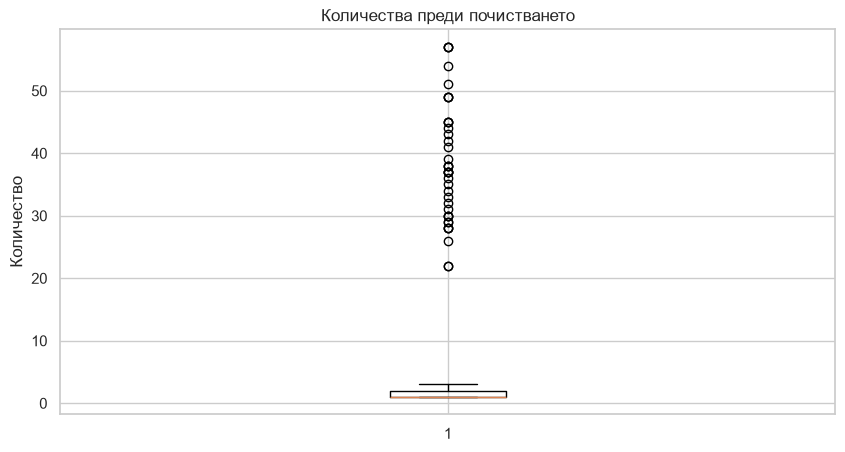

In [52]:
plt.boxplot(order_items["Quantity"])
plt.title("Количества преди почистването")
plt.ylabel("Количество")
plt.show()

#### IQR

In [53]:
Q1 = order_items["Quantity"].quantile(0.25)
Q3 = order_items["Quantity"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Долна граница:", lower)
print("Горна граница:", upper)

Q1: 1.0
Q3: 2.0
IQR: 1.0
Долна граница: -0.5
Горна граница: 3.5


#### Outliers според IQR

In [54]:
outliers = order_items[
    (order_items["Quantity"] < lower) |
    (order_items["Quantity"] > upper)
]

print(outliers.head(10))
print("Брой outliers:", len(outliers))

      OrderID ProductID  Quantity  UnitPrice  LineTotal
784     10524       P24        54     129.00    6966.00
2092    11382       P14        37     101.15    3742.55
2372    11573       P26        44      67.15    2954.60
3625    12394       P25        37      89.00    3293.00
4398    12903       P25        42      89.00    3738.00
4504    12983       P11        45      35.00    1575.00
4855    13223       P23        51     189.00    9639.00
6325    14230       P26        37      79.00    2923.00
6559    14382       P24        22     129.00    2838.00
6880    14595       P27        32      49.00    1568.00
Брой outliers: 40


#### Z-score

In [55]:
order_items["Z_score"] = zscore(order_items["Quantity"])

outliers_z = order_items[order_items["Z_score"].abs() > 3]
print("Брой outliers според Z-score:", len(outliers_z))
print("Същите редове като при IQR:", list(outliers_z.index) == list(outliers.index))

Брой outliers според Z-score: 40
Същите редове като при IQR: True


#### Почистване

Всички открити редове са с количество над 20 при обичайни 1 до 3, затова ги приемам за грешки при въвеждане и ги премахвам.

In [56]:
order_items_clean = order_items[
    (order_items["Quantity"] >= lower) &
    (order_items["Quantity"] <= upper)
]

print("Преди:", order_items.shape[0])
print("След:", order_items_clean.shape[0])

Преди: 26998
След: 26958


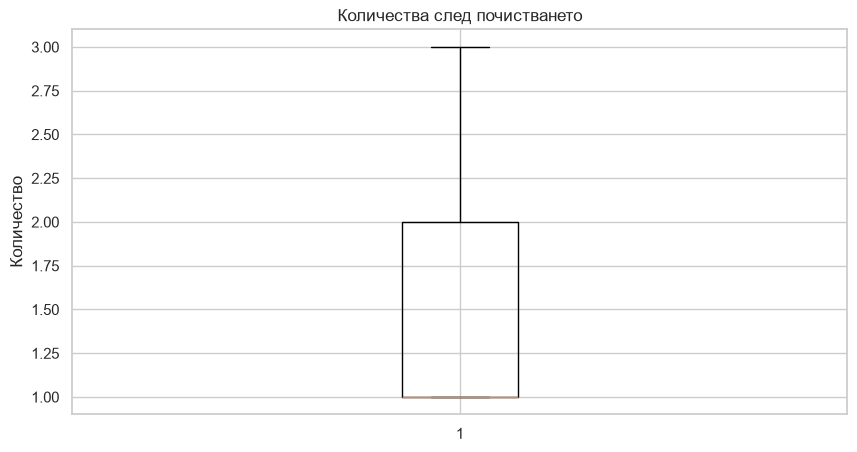

In [57]:
plt.boxplot(order_items_clean["Quantity"])
plt.title("Количества след почистването")
plt.ylabel("Количество")
plt.show()

#### Сравнение преди и след

In [58]:
comparison = pd.DataFrame({
    "Преди": order_items["Quantity"].describe(),
    "След": order_items_clean["Quantity"].describe()
})
print(comparison)

              Преди          След
count  26998.000000  26958.000000
mean       1.504482      1.449885
std        1.621189      0.698803
min        1.000000      1.000000
25%        1.000000      1.000000
50%        1.000000      1.000000
75%        2.000000      2.000000
max       57.000000      3.000000


#### Запазване на почистените данни

In [59]:
order_items = order_items_clean.drop(columns=["Z_score"])

#### Поръчки без редове

Няколко поръчки са имали само един ред и той е бил премахнат. Махам и тях, и мненията към тях.

In [60]:
print("Поръчки без редове:", (~orders["OrderID"].isin(order_items["OrderID"])).sum())

orders = orders[orders["OrderID"].isin(order_items["OrderID"])]
reviews = reviews[reviews["OrderID"].isin(orders["OrderID"])]

Поръчки без редове: 14


### 2.8. Отклоняващи се стойности в стойността на реда

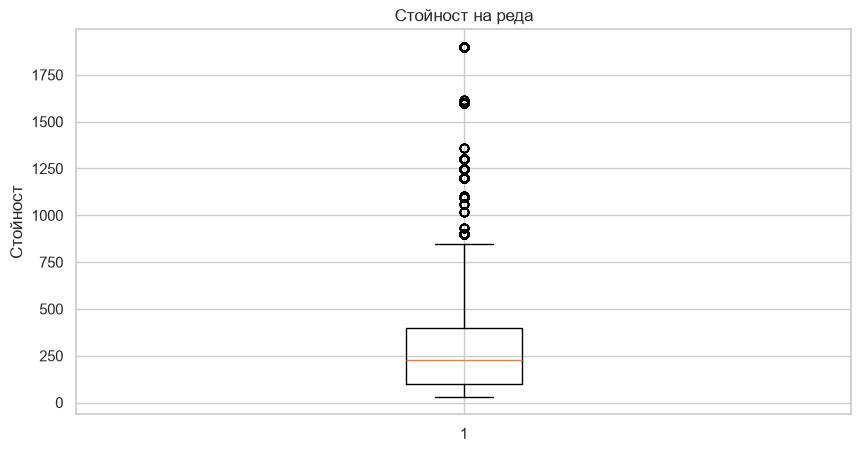

In [61]:
plt.boxplot(order_items["LineTotal"])
plt.title("Стойност на реда")
plt.ylabel("Стойност")
plt.show()

Тук IQR също отбелязва редове, но те са скъпи продукти, а не грешки. Затова не ги премахвам.

In [62]:
Q1 = order_items["LineTotal"].quantile(0.25)
Q3 = order_items["LineTotal"].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR

expensive = order_items[order_items["LineTotal"] > upper]
print("Горна граница:", upper)
print("Брой редове над границата:", len(expensive))
print(expensive.merge(products, on="ProductID")["Product"].value_counts())

Горна граница: 850.5
Брой редове над границата: 2927
Product
Климатик             607
Съдомиялна           453
Хладилник            436
Телевизор            399
Смартфон             382
Настолен компютър    327
Лаптоп               323
Name: count, dtype: int64


### 2.9. Размер на таблиците преди и след почистването

In [63]:
comparison = pd.DataFrame({
    "Преди": rows_before,
    "След": [customers.shape[0], orders.shape[0], order_items.shape[0], reviews.shape[0]]
}, index=["Клиенти", "Поръчки", "Детайли на поръчките", "Мнения"])
print(comparison)

                      Преди   След
Клиенти                2040   2000
Поръчки               18088  17984
Детайли на поръчките  26998  26958
Мнения                 1475   1434


### 2.10. Обща таблица за анализа

Свързвам детайлите с поръчките, продуктите и клиентите. `merge` добавя към всеки ред колоните от другата таблица по общата колона, посочена в `on`.

In [64]:
order_lines = order_items.merge(orders, on="OrderID")
order_lines = order_lines.merge(products[["ProductID", "Product", "Category", "Cost"]], on="ProductID")
order_lines = order_lines.merge(customers[["CustomerID", "Age", "City", "CustomerCategory"]], on="CustomerID")

print(order_lines.shape)
print(order_lines.head())

(26958, 15)
   OrderID ProductID  Quantity  UnitPrice  LineTotal CustomerID       Date  \
0    10001       P10         2      149.0      298.0      C1501 2025-11-01   
1    10002       P24         1      129.0      129.0      C0119 2025-11-01   
2    10003       P08         1      649.0      649.0      C1774 2025-11-01   
3    10004       P24         2      129.0      258.0      C1339 2025-11-01   
4    10004       P13         1      349.0      349.0      C1339 2025-11-01   

      Status   PaymentMethod            Product                Category  Cost  \
0  Доставена           Карта  Безжични слушалки      Телефони и таблети    85   
1  Доставена           Карта          Конвектор  Малки домакински уреди    80   
2  Доставена  Наложен платеж             Таблет      Телефони и таблети   545   
3   Отказана  Наложен платеж          Конвектор  Малки домакински уреди    80   
4   Отказана  Наложен платеж           Саундбар      Телевизори и аудио   250   

   Age     City CustomerCategory

#### Производни показатели

In [65]:
order_lines["Revenue"] = order_lines["LineTotal"]
order_lines["Profit"] = order_lines["Revenue"] - order_lines["Cost"] * order_lines["Quantity"]
order_lines["Margin"] = order_lines["Profit"] / order_lines["Revenue"]

print(order_lines[["Revenue", "Cost", "Quantity", "Profit", "Margin"]].head())

   Revenue  Cost  Quantity  Profit    Margin
0    298.0    85         2   128.0  0.429530
1    129.0    80         1    49.0  0.379845
2    649.0   545         1   104.0  0.160247
3    258.0    80         2    98.0  0.379845
4    349.0   250         1    99.0  0.283668


#### Продажби

За приходи и печалба броя само доставените поръчки. Отказаните и върнатите не носят приход.

In [66]:
print(order_lines["Status"].value_counts())

sales = order_lines[order_lines["Status"] == "Доставена"].copy()
print("Редове в продажбите:", len(sales))

Status
Доставена    23937
Отказана      2228
Върната        793
Name: count, dtype: int64
Редове в продажбите: 23937


### 2.11. Кодиране на категориалните характеристики

#### Label Encoding на категорията на продукта

In [67]:
le = LabelEncoder()
sales["Category_encoded"] = le.fit_transform(sales["Category"])

print(sales[["Category", "Category_encoded"]].drop_duplicates())
print("Класове:", list(le.classes_))

                     Category  Category_encoded
0          Телефони и таблети                 4
1      Малки домакински уреди                 2
5                    Компютри                 1
25  Голяма домакинска техника                 0
32         Телевизори и аудио                 3
Класове: ['Голяма домакинска техника', 'Компютри', 'Малки домакински уреди', 'Телевизори и аудио', 'Телефони и таблети']


#### One-Hot Encoding на начина на плащане

In [68]:
payment_onehot = pd.get_dummies(sales[["OrderID", "PaymentMethod"]], columns=["PaymentMethod"])
print(payment_onehot.head())

   OrderID  PaymentMethod_Банков превод  PaymentMethod_Карта  \
0    10001                        False                 True   
1    10002                        False                 True   
2    10003                        False                False   
5    10005                        False                False   
6    10006                        False                False   

   PaymentMethod_Наложен платеж  PaymentMethod_Неизвестен  
0                         False                     False  
1                         False                     False  
2                          True                     False  
5                          True                     False  
6                          True                     False  


### 2.12. Нормализация и стандартизация

Тук показвам двата метода върху числовите колони. В моделите ги прилагам там, където са нужни: MinMaxScaler за LSTM в Етап 4 и StandardScaler за K-means в Етап 6.

In [69]:
numeric = ["Quantity", "UnitPrice", "Revenue"]
print(sales[numeric].describe())

           Quantity     UnitPrice       Revenue
count  23937.000000  23937.000000  23937.000000
mean       1.453482    320.762391    358.873777
std        0.699815    399.489931    385.114557
min        1.000000     29.750000     29.750000
25%        1.000000     69.000000     98.000000
50%        1.000000    129.000000    229.000000
75%        2.000000    389.000000    399.000000
max        3.000000   1899.000000   1899.000000


#### Min-Max нормализация

In [70]:
mm = MinMaxScaler()
sales_mm = pd.DataFrame(
    mm.fit_transform(sales[numeric]),
    columns=numeric
)
print(sales_mm.describe())

           Quantity     UnitPrice       Revenue
count  23937.000000  23937.000000  23937.000000
mean       0.226741      0.155684      0.176073
std        0.349908      0.213717      0.206026
min        0.000000      0.000000      0.000000
25%        0.000000      0.020998      0.036512
50%        0.000000      0.053096      0.106594
75%        0.500000      0.192189      0.197539
max        1.000000      1.000000      1.000000


#### Стандартизация

In [71]:
ss = StandardScaler()
sales_std = pd.DataFrame(
    ss.fit_transform(sales[numeric]),
    columns=numeric
)
print("mean:", sales_std.mean().round(6).to_dict())
print("std: ", sales_std.std(ddof=0).round(6).to_dict())

mean: {'Quantity': -0.0, 'UnitPrice': 0.0, 'Revenue': 0.0}
std:  {'Quantity': 1.0, 'UnitPrice': 1.0, 'Revenue': 1.0}


## Етап 3. Статистически анализ

### 3.1. Стойност на поръчка

Една поръчка има един или няколко реда, затова събирам приходите по `OrderID`.

In [72]:
order_values = sales.groupby("OrderID")["Revenue"].sum()
print(order_values.head())
print("Брой поръчки:", len(order_values))

OrderID
10001    298.0
10002    129.0
10003    649.0
10005    207.0
10006    777.0
Name: Revenue, dtype: float64
Брой поръчки: 16021


### 3.2. Описателна статистика

In [73]:
def print_statistics(column):
    print("Средна:", column.mean())
    print("Медиана:", column.median())
    print("Мода:", column.mode().tolist())
    print("Минимум:", column.min())
    print("Максимум:", column.max())
    print("Дисперсия:", column.var())
    print("Стандартно отклонение:", column.std())
    print("Q1:", column.quantile(0.25))
    print("Q2:", column.quantile(0.50))
    print("Q3:", column.quantile(0.75))

#### Цена

In [74]:
print_statistics(sales["UnitPrice"])

Средна: 320.76239085933906
Медиана: 129.0
Мода: [35.0]
Минимум: 29.75
Максимум: 1899.0
Дисперсия: 159592.20457949827
Стандартно отклонение: 399.48993051076803
Q1: 69.0
Q2: 129.0
Q3: 389.0


#### Количество

In [75]:
print_statistics(sales["Quantity"])

Средна: 1.4534820570664662
Медиана: 1.0
Мода: [1]
Минимум: 1
Максимум: 3
Дисперсия: 0.4897414885755142
Стандартно отклонение: 0.6998153246217992
Q1: 1.0
Q2: 1.0
Q3: 2.0


#### Стойност на поръчка

In [76]:
print_statistics(order_values)

Средна: 536.1938455776793
Медиана: 349.0
Мода: [599.0]
Минимум: 29.75
Максимум: 4597.0
Дисперсия: 274789.05981730175
Стандартно отклонение: 524.2032619292842
Q1: 147.0
Q2: 349.0
Q3: 749.0


### 3.3. Разпределение на цените

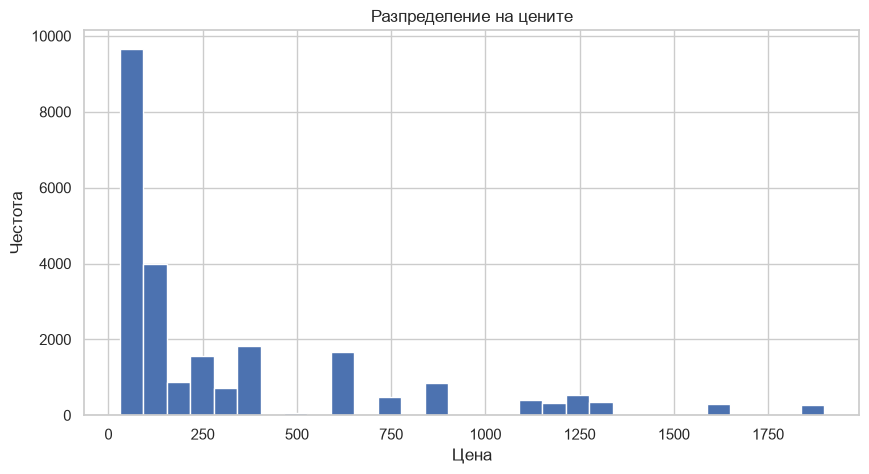

In [77]:
plt.hist(sales["UnitPrice"], bins=30)
plt.title("Разпределение на цените")
plt.xlabel("Цена")
plt.ylabel("Честота")
plt.show()

### 3.4. Разпределение на количествата

Количеството приема само стойностите 1, 2 и 3, затова използвам стълбовидна графика.

In [78]:
quantity_counts = sales["Quantity"].value_counts()
print(quantity_counts)

Quantity
1    15977
2     5065
3     2895
Name: count, dtype: int64


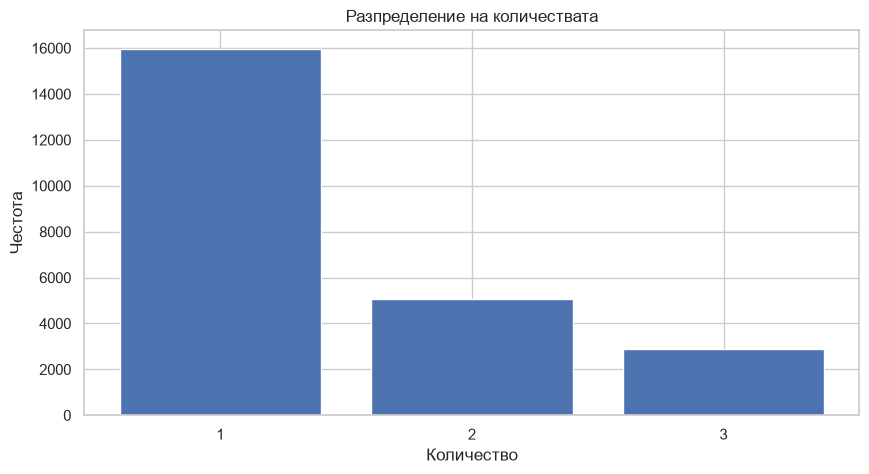

In [79]:
plt.bar(quantity_counts.index, quantity_counts.values)
plt.title("Разпределение на количествата")
plt.xlabel("Количество")
plt.ylabel("Честота")
plt.xticks(quantity_counts.index)
plt.show()

### 3.5. Разпределение на стойностите на поръчките

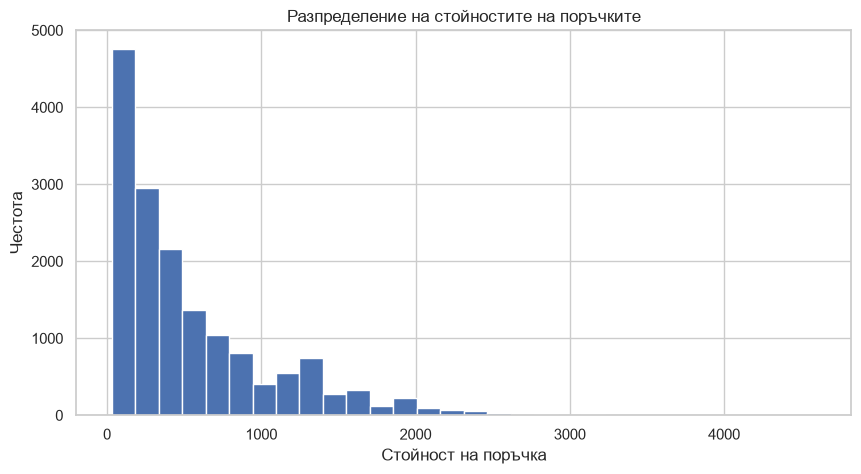

In [80]:
plt.hist(order_values, bins=30)
plt.title("Разпределение на стойностите на поръчките")
plt.xlabel("Стойност на поръчка")
plt.ylabel("Честота")
plt.show()

### 3.6. Извод за разпределението

In [81]:
mean_value = order_values.mean()
median_value = order_values.median()

print(f"Средна: {mean_value:.2f}")
print(f"Медиана: {median_value:.2f}")

if mean_value > median_value:
    print("Дясна асиметрия (mean > median).")
elif mean_value < median_value:
    print("Лява асиметрия (mean < median).")
else:
    print("Симетрично разпределение.")

Средна: 536.19
Медиана: 349.00
Дясна асиметрия (mean > median).


Половината поръчки са под 349 евро, но малък брой скъпи поръчки (компютри, телевизори, климатици) дърпат средната нагоре. Затова за типична поръчка е по-добре да се гледа медианата.

### 3.7. Нормално разпределение

Броят поръчки на ден се групира около една средна стойност, затова го сравнявам с нормално разпределение със същата средна и стандартно отклонение.

In [82]:
daily_orders = orders.groupby("Date")["OrderID"].count()

mu = daily_orders.mean()
sigma = daily_orders.std()

print("Средно поръчки на ден:", mu)
print("Стандартно отклонение:", sigma)

Средно поръчки на ден: 49.271232876712325
Стандартно отклонение: 18.482999907042995


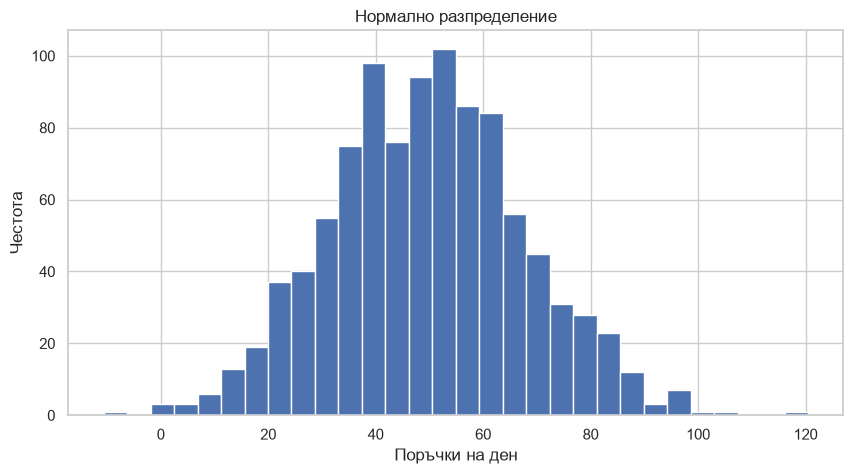

In [83]:
np.random.seed(42)
data_normal = np.random.normal(loc=mu, scale=sigma, size=1000)

plt.hist(data_normal, bins=30)
plt.title("Нормално разпределение")
plt.xlabel("Поръчки на ден")
plt.ylabel("Честота")
plt.show()

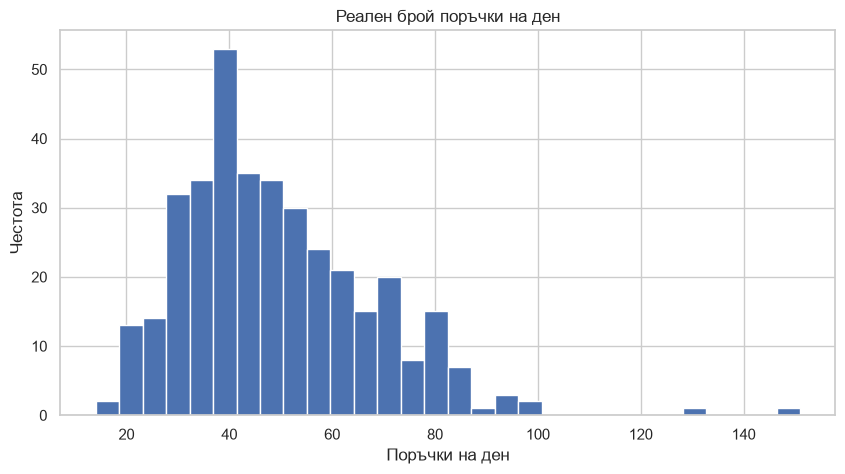

In [84]:
plt.hist(daily_orders, bins=30)
plt.title("Реален брой поръчки на ден")
plt.xlabel("Поръчки на ден")
plt.ylabel("Честота")
plt.show()

#### Вероятност за слаб и за силен ден

In [85]:
p_weak = norm.cdf(30, loc=mu, scale=sigma)
p_strong = 1 - norm.cdf(70, loc=mu, scale=sigma)

print("P(X <= 30) =", p_weak)
print("P(X > 70) =", p_strong)

print("Реален дял на дните с до 30 поръчки:", (daily_orders <= 30).mean())
print("Реален дял на дните с над 70 поръчки:", (daily_orders > 70).mean())

P(X <= 30) = 0.14855605093817204
P(X > 70) = 0.13103659369319975
Реален дял на дните с до 30 поръчки: 0.1232876712328767
Реален дял на дните с над 70 поръчки: 0.136986301369863


#### Плътност и граница

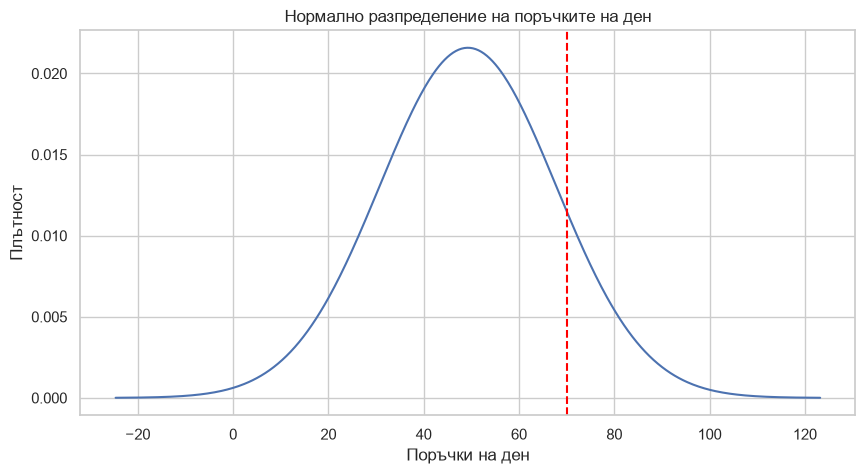

In [86]:
x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 500)
y = norm.pdf(x, mu, sigma)

plt.plot(x, y)
plt.axvline(70, color="red", linestyle="--")
plt.title("Нормално разпределение на поръчките на ден")
plt.xlabel("Поръчки на ден")
plt.ylabel("Плътност")
plt.show()

### 3.8. Равномерно разпределение

Възрастта на клиентите е между 18 и 70 години и е разпределена почти по равно, затова я сравнявам с равномерно разпределение. Връхът в средата е от липсващите възрасти, които замених с медианата.

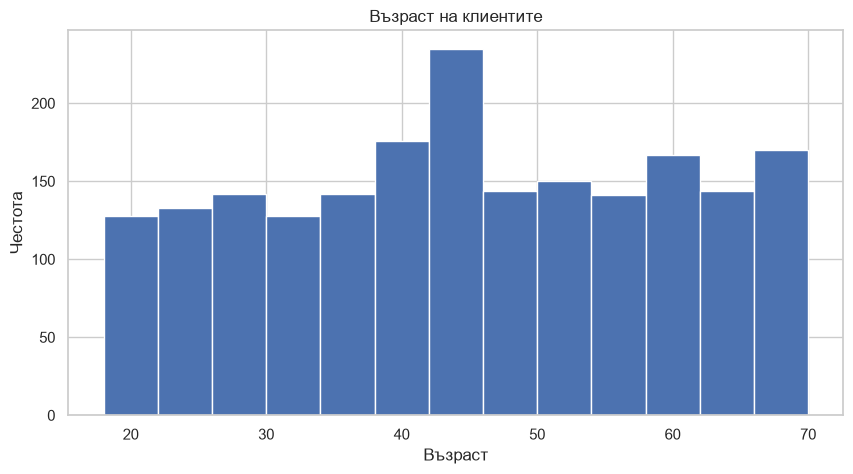

In [87]:
plt.hist(customers["Age"], bins=13)
plt.title("Възраст на клиентите")
plt.xlabel("Възраст")
plt.ylabel("Честота")
plt.show()

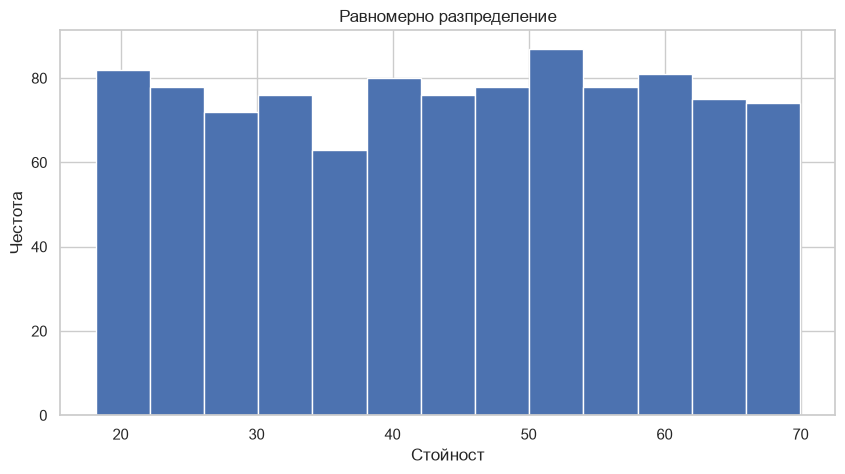

In [88]:
data_uniform = np.random.uniform(low=18, high=70, size=1000)

plt.hist(data_uniform, bins=13)
plt.title("Равномерно разпределение")
plt.xlabel("Стойност")
plt.ylabel("Честота")
plt.show()

#### Вероятност клиент да е до 30 години

In [89]:
p_young = uniform.cdf(30, loc=18, scale=52)

print("P(X <= 30) =", p_young)
print("Реален дял на клиентите до 30 години:", (customers["Age"] <= 30).mean())

P(X <= 30) = 0.23076923076923078
Реален дял на клиентите до 30 години: 0.2175


### 3.9. Биномиално разпределение

Всяка поръчка или се отказва, или не. При 20 поръчки броят на отказаните следва биномиално разпределение.

In [90]:
n = 20
p = (orders["Status"] == "Отказана").mean()
print("Дял на отказаните поръчки:", p)

Дял на отказаните поръчки: 0.08274021352313167


In [91]:
p_none = binom.pmf(0, n, p)
p_at_least_three = 1 - binom.cdf(2, n, p)

print("P(X = 0) =", p_none)
print("P(X >= 3) =", p_at_least_three)

P(X = 0) = 0.1777653372098742
P(X >= 3) = 0.2267123126340561


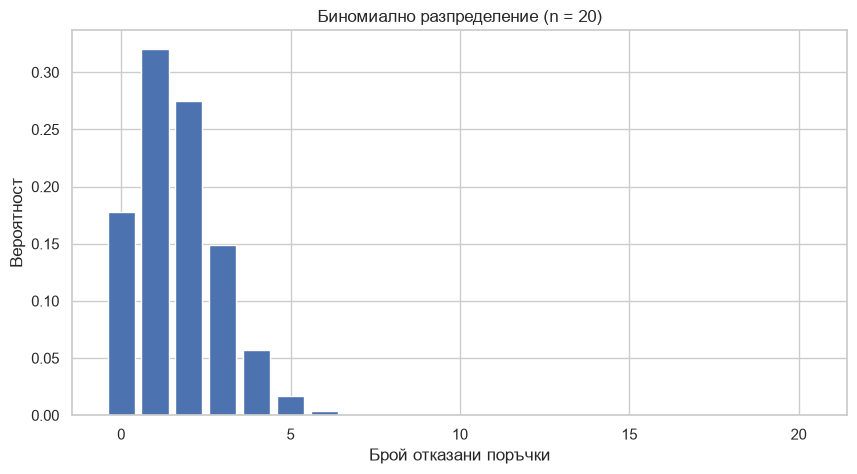

In [92]:
x_binom = np.arange(0, n + 1)
probabilities = binom.pmf(x_binom, n, p)

plt.bar(x_binom, probabilities)
plt.title("Биномиално разпределение (n = 20)")
plt.xlabel("Брой отказани поръчки")
plt.ylabel("Вероятност")
plt.show()

### 3.10. Корелации между показателите на продажбите

#### Pearson корелационна матрица

In [93]:
numeric_columns = ["Quantity", "UnitPrice", "Cost", "Revenue", "Profit"]

correlation_matrix = sales[numeric_columns].corr(method="pearson")
print(correlation_matrix)

           Quantity  UnitPrice      Cost   Revenue    Profit
Quantity   1.000000  -0.383995 -0.372619 -0.246236 -0.006309
UnitPrice -0.383995   1.000000  0.997592  0.984825  0.810828
Cost      -0.372619   0.997592  1.000000  0.982799  0.782660
Revenue   -0.246236   0.984825  0.982799  1.000000  0.873115
Profit    -0.006309   0.810828  0.782660  0.873115  1.000000


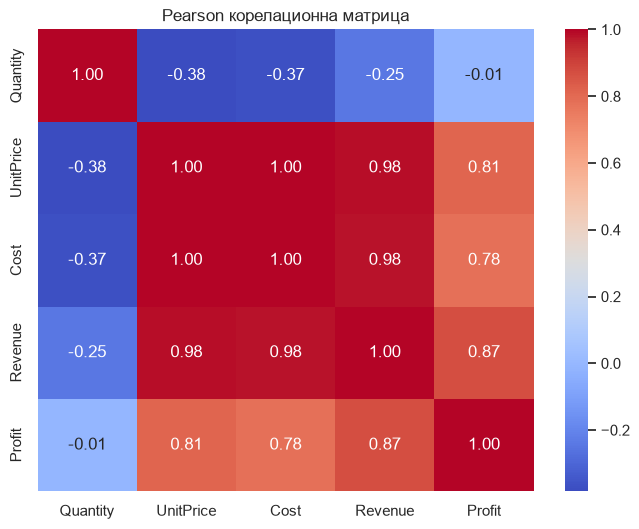

In [94]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Pearson корелационна матрица")
plt.show()

#### Spearman корелационна матрица

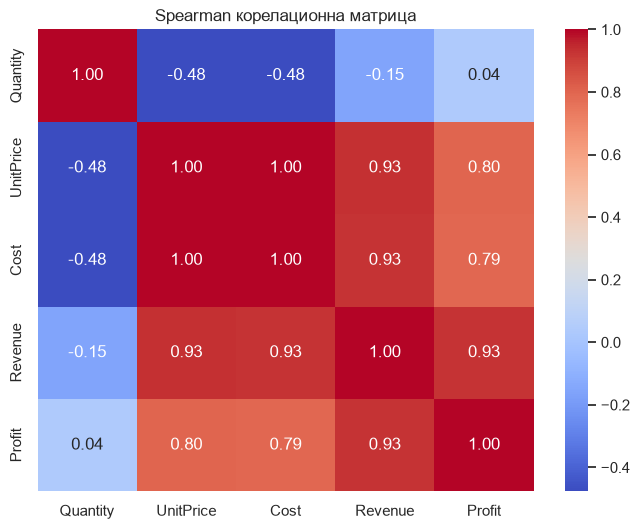

In [95]:
spearman_matrix = sales[numeric_columns].corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(spearman_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Spearman корелационна матрица")
plt.show()

### 3.11. Цена и количество

In [96]:
pearson_r, pearson_p = pearsonr(sales["UnitPrice"], sales["Quantity"])
spearman_rho, spearman_p = spearmanr(sales["UnitPrice"], sales["Quantity"])

print("Pearson r:      ", pearson_r)
print("Pearson p-value:", pearson_p)
print("Spearman rho:   ", spearman_rho)
print("Spearman p:     ", spearman_p)

Pearson r:       -0.3839947210233133
Pearson p-value: 0.0
Spearman rho:    -0.47669305504051335
Spearman p:      0.0


Количеството приема само три стойности, затова вместо scatter plot показвам средната цена за всяко количество.

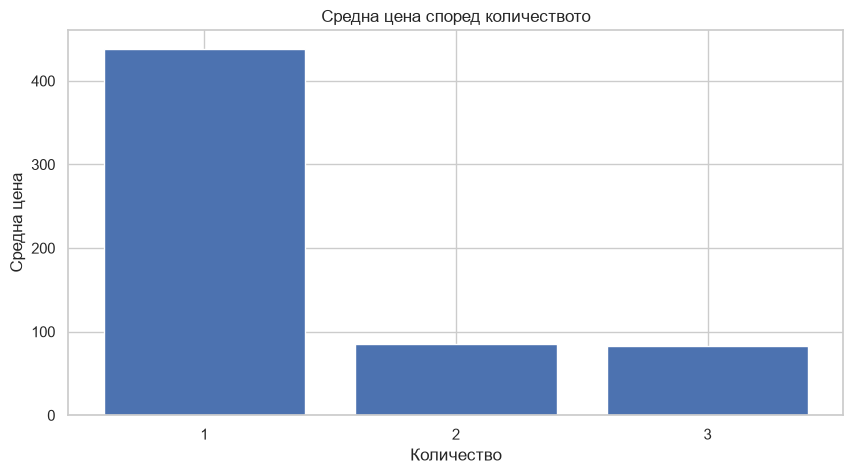

In [97]:
price_by_quantity = sales.groupby("Quantity")["UnitPrice"].mean()

plt.bar(price_by_quantity.index, price_by_quantity.values)
plt.xlabel("Количество")
plt.ylabel("Средна цена")
plt.title("Средна цена според количеството")
plt.xticks(price_by_quantity.index)
plt.show()

### 3.12. Показатели по клиенти

In [98]:
customer_stats = sales.groupby("CustomerID").agg(
    Orders=("OrderID", "nunique"),
    Revenue=("Revenue", "sum")
)
customer_stats = customer_stats.merge(customers[["CustomerID", "Age"]], on="CustomerID")
print(customer_stats.head())

  CustomerID  Orders  Revenue  Age
0      C0001      25  6331.45   35
1      C0002       3  2094.00   61
2      C0003       5  3298.00   20
3      C0004      10  3719.00   50
4      C0005      12  6123.00   63


#### Брой поръчки и приход

In [99]:
r_orders, p_orders = pearsonr(customer_stats["Orders"], customer_stats["Revenue"])
rho_orders, p_orders_s = spearmanr(customer_stats["Orders"], customer_stats["Revenue"])

print("Pearson r:   ", r_orders)
print("Spearman rho:", rho_orders)

Pearson r:    0.9434856887804883
Spearman rho: 0.8904531613154102


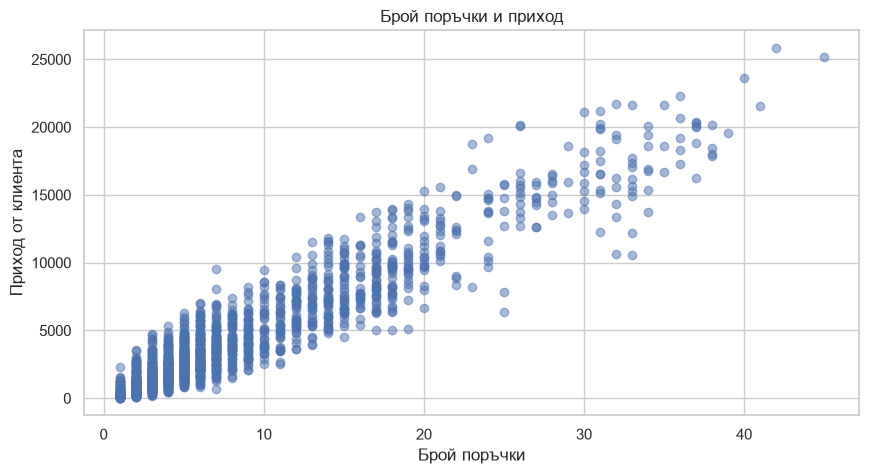

In [100]:
plt.scatter(customer_stats["Orders"], customer_stats["Revenue"], alpha=0.5)
plt.xlabel("Брой поръчки")
plt.ylabel("Приход от клиента")
plt.title("Брой поръчки и приход")
plt.show()

#### Възраст и приход

In [101]:
r_age, p_age = pearsonr(customer_stats["Age"], customer_stats["Revenue"])
rho_age, p_age_s = spearmanr(customer_stats["Age"], customer_stats["Revenue"])

print("Pearson r:   ", r_age)
print("p-value:     ", p_age)
print("Spearman rho:", rho_age)

Pearson r:    -0.01016145613594665
p-value:      0.6541670256309735
Spearman rho: -0.021121593781161678


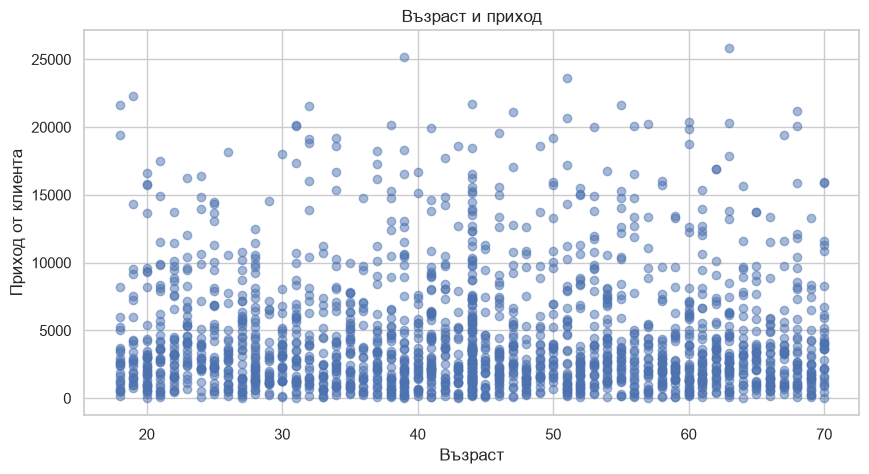

In [102]:
plt.scatter(customer_stats["Age"], customer_stats["Revenue"], alpha=0.5)
plt.xlabel("Възраст")
plt.ylabel("Приход от клиента")
plt.title("Възраст и приход")
plt.show()

### 3.13. Интерпретация

- Цената и себестойността са почти напълно свързани, защото цената се образува от себестойността плюс надценка.
- Цената и количеството имат умерена отрицателна връзка. Това не значи, че по-ниска цена на лаптопа би довела до покупка на три лаптопа. Причината е видът на продукта: евтините стоки (зарядни, мишки, кани) се купуват по няколко, а скъпите по една.
- Броят поръчки и приходът от клиента са силно свързани, но и тук корелацията не доказва причина. И двете зависят от това колко активен е клиентът.
- В тези данни възрастта и приходът не са свързани (коефициент около 0 и висока p-стойност).
- При цена и количество Spearman е по-силен от Pearson, което показва, че връзката е монотонна, но не е линейна.

## Етап 4. Анализ и прогнозиране на времеви серии

### 4.1. Дневни приходи и брой поръчки

In [103]:
df = sales.groupby("Date").agg(
    Sales=("Revenue", "sum"),
    Orders=("OrderID", "nunique")
)
print(df.head())

              Sales  Orders
Date                       
2025-11-01  25356.0      51
2025-11-02  23196.0      46
2025-11-03  11130.0      23
2025-11-04  16529.0      27
2025-11-05  11543.0      22


### 4.2. Проверка на времевия индекс

In [104]:
df = df.sort_index()

print("Начало:", df.index.min())
print("Край:  ", df.index.max())
print("Монотонно нарастващ:", df.index.is_monotonic_increasing)

Начало: 2025-11-01 00:00:00
Край:   2026-10-31 00:00:00
Монотонно нарастващ: True


#### Честота на наблюденията

In [105]:
print(df.index.to_series().diff().value_counts())

Date
1 days    364
Name: count, dtype: int64


### 4.3. Липсващи периоди

In [106]:
full_index = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="D"
)
df = df.reindex(full_index)
df.index.name = "Date"

print("Брой дни:", len(df))
print("Липсващи след reindex:")
print(df.isna().sum())

Брой дни: 365
Липсващи след reindex:
Sales     0
Orders    0
dtype: int64


Няма ден без продажби. Оставям интерполацията, за да работи кодът и при данни с пропуснати дни.

In [107]:
df["Sales"] = df["Sales"].interpolate()
df["Orders"] = df["Orders"].interpolate()

### 4.4. Дневни приходи

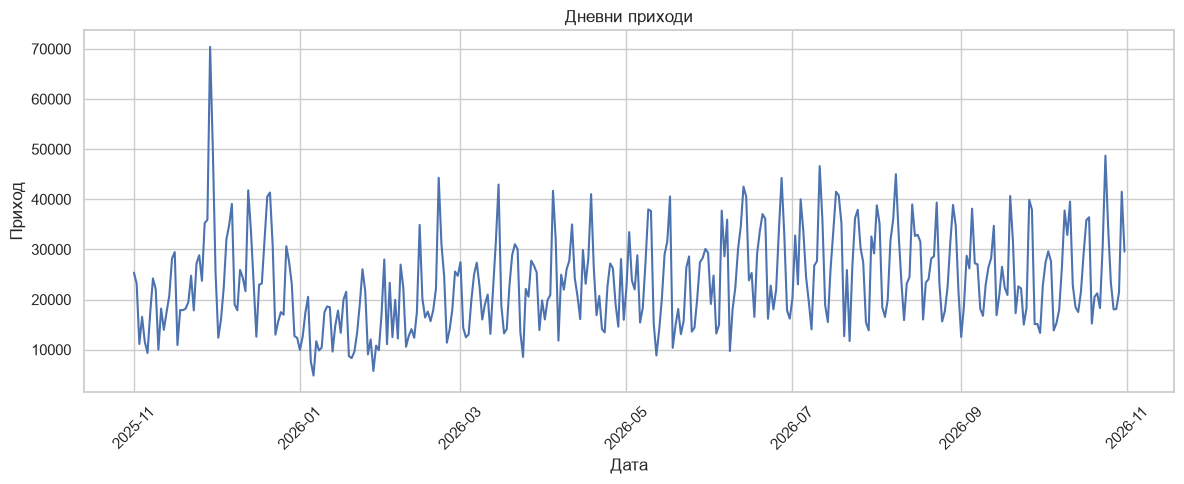

In [108]:
plt.figure(figsize=(12, 5))
plt.plot(df.index, df["Sales"])
plt.title("Дневни приходи")
plt.xlabel("Дата")
plt.ylabel("Приход")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.5. Дневен брой поръчки

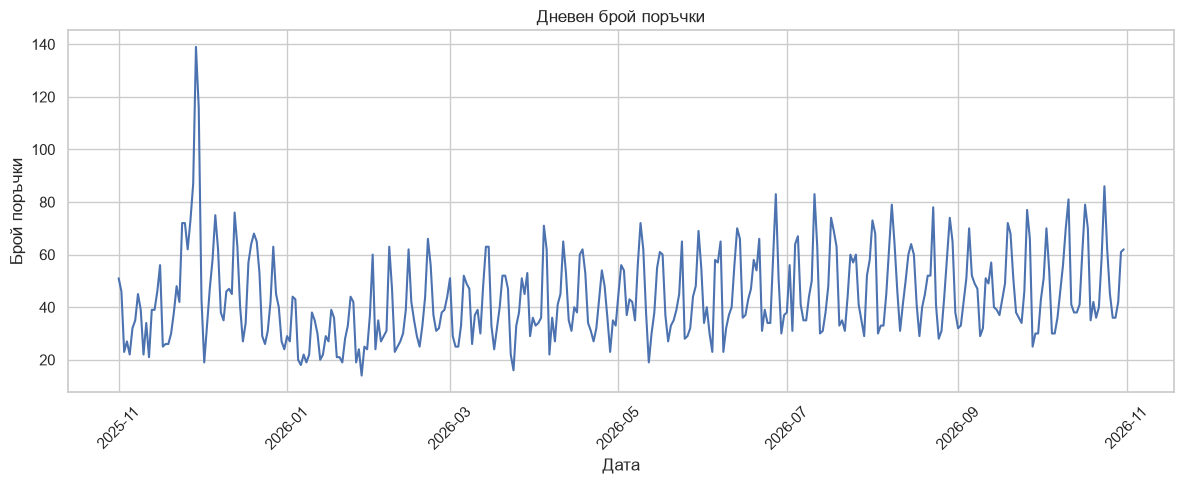

In [109]:
plt.figure(figsize=(12, 5))
plt.plot(df.index, df["Orders"])
plt.title("Дневен брой поръчки")
plt.xlabel("Дата")
plt.ylabel("Брой поръчки")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.6. Сезонност по ден от седмицата

In [110]:
df["DayOfWeek"] = df.index.day_of_week

weekly = df.groupby("DayOfWeek")[["Sales", "Orders"]].mean()
print("Средни стойности по ден от седмицата (0 = понеделник):")
print(weekly)

Средни стойности по ден от седмицата (0 = понеделник):
                  Sales     Orders
DayOfWeek                         
0          17954.223077  34.269231
1          16832.977885  31.730769
2          17660.137500  32.326923
3          21186.933654  38.884615
4          26067.608654  48.961538
5          33878.326415  62.754717
6          30967.548077  57.961538


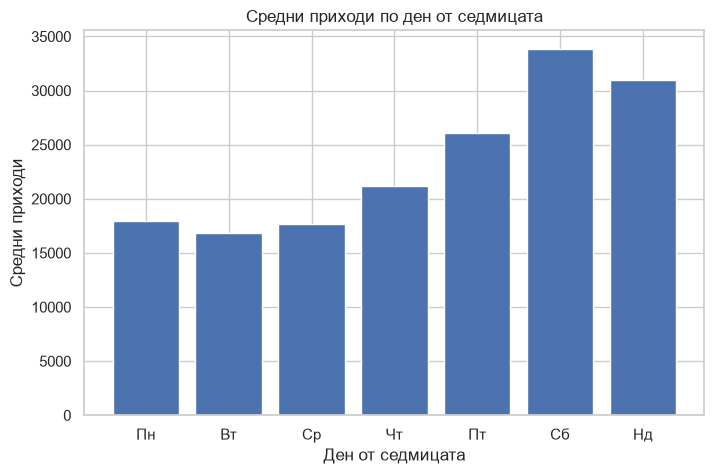

In [111]:
plt.figure(figsize=(8, 5))
plt.bar(weekly.index, weekly["Sales"])
plt.title("Средни приходи по ден от седмицата")
plt.xlabel("Ден от седмицата")
plt.ylabel("Средни приходи")
plt.xticks(range(7), ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Нд"])
plt.show()

### 4.7. Ресемплиране

#### Седмични приходи

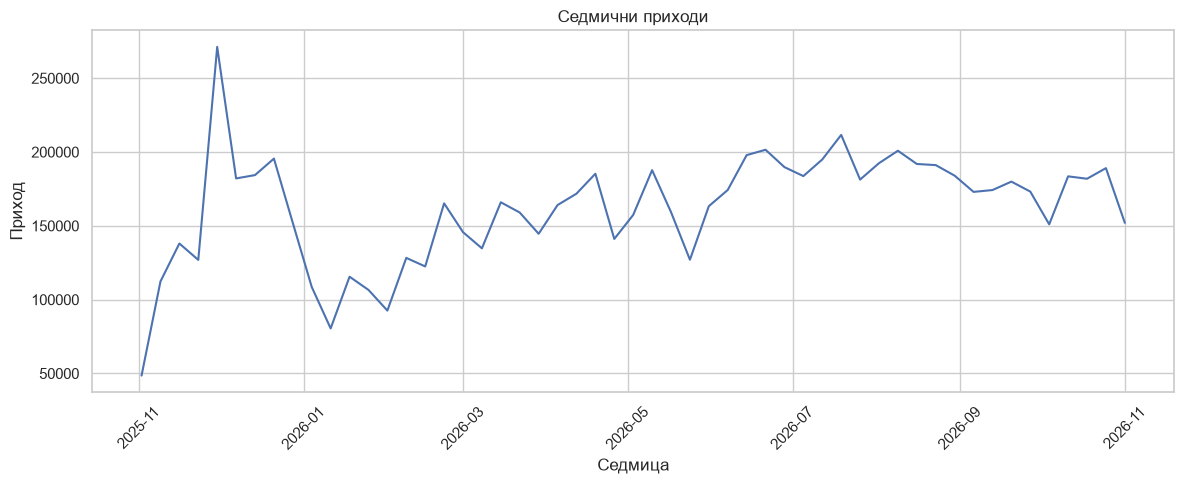

In [112]:
weekly_sales = df["Sales"].resample("W").sum()

plt.figure(figsize=(12, 5))
plt.plot(weekly_sales.index, weekly_sales.values)
plt.title("Седмични приходи")
plt.xlabel("Седмица")
plt.ylabel("Приход")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Месечни приходи и поръчки

In [113]:
monthly_sales = df[["Sales", "Orders"]].resample("ME").sum()
print(monthly_sales)

               Sales  Orders
Date                        
2025-11-30  696967.6    1433
2025-12-31  762068.0    1422
2026-01-31  427549.0     871
2026-02-28  562186.0    1073
2026-03-31  665430.0    1220
2026-04-30  706194.0    1240
2026-05-31  716968.0    1389
2026-06-30  797453.0    1370
2026-07-31  855982.0    1495
2026-08-31  863375.0    1556
2026-09-30  722269.0    1375
2026-10-31  813920.0    1577


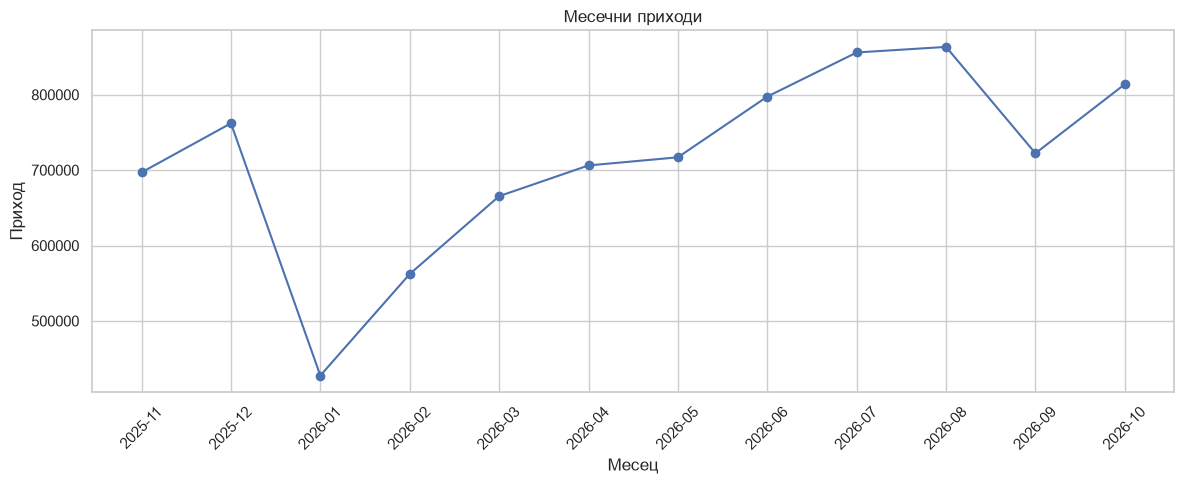

In [114]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index.strftime("%Y-%m"), monthly_sales["Sales"], marker="o")
plt.title("Месечни приходи")
plt.xlabel("Месец")
plt.ylabel("Приход")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Виждат се четири неща: връх в седмицата на Черния петък и силен декември, спад през януари, постепенен ръст до август и нов спад през септември. През седмицата най-силни са петък, събота и неделя.

### 4.8. Train/Test разделяне

In [115]:
split_date = "2026-09-01"

train = df.loc[df.index < split_date]
test = df.loc[df.index >= split_date]

print("Train:", train.shape)
print("Test: ", test.shape)

Train: (304, 3)
Test:  (61, 3)


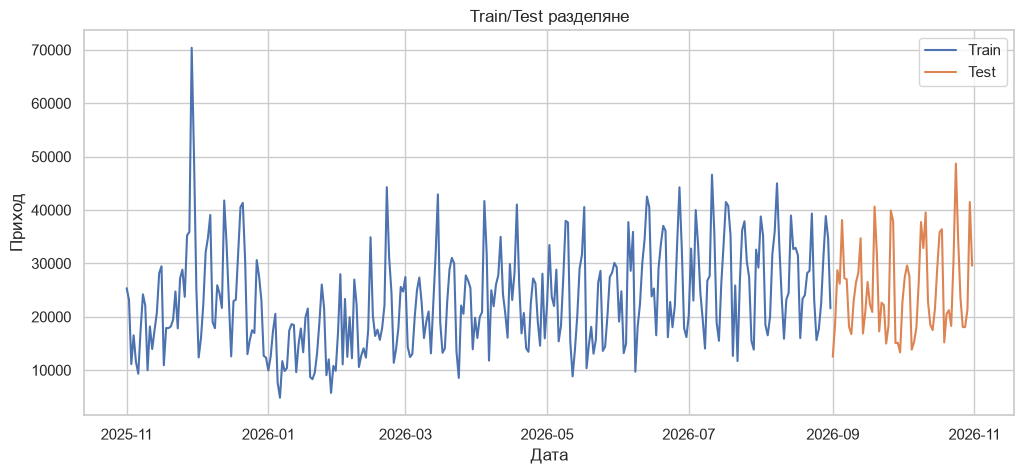

In [116]:
plt.figure(figsize=(12, 5))
plt.plot(train.index, train["Sales"], label="Train")
plt.plot(test.index, test["Sales"], label="Test")
plt.title("Train/Test разделяне")
plt.xlabel("Дата")
plt.ylabel("Приход")
plt.legend()
plt.show()

### 4.9. Базови модели

#### Naive Forecast (последна наблюдавана стойност)

In [117]:
last_value = train["Sales"].iloc[-1]
naive_forecast = np.repeat(last_value, len(test))

print("Последна стойност в train:", last_value)

Последна стойност в train: 21588.0


#### Moving Average (пълзяща средна за 7 дни)

In [118]:
window = 7

moving_average = (
    train["Sales"]
    .rolling(window)
    .mean()
    .iloc[-1]
)

ma_forecast = np.repeat(moving_average, len(test))
print("Moving average (последна):", moving_average)

Moving average (последна): 26051.571428571428


#### Linear Regression

In [119]:
X_train = np.arange(len(train)).reshape(-1, 1)
y_train = train["Sales"].values

X_test = np.arange(
    len(train),
    len(train) + len(test)
).reshape(-1, 1)

model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

linear_forecast = model_lr.predict(X_test)

print("Intercept:", model_lr.intercept_)
print("Slope:    ", model_lr.coef_[0])

Intercept: 18952.19465271786
Slope:     28.068121972680434


#### Сравнение на трите прогнози

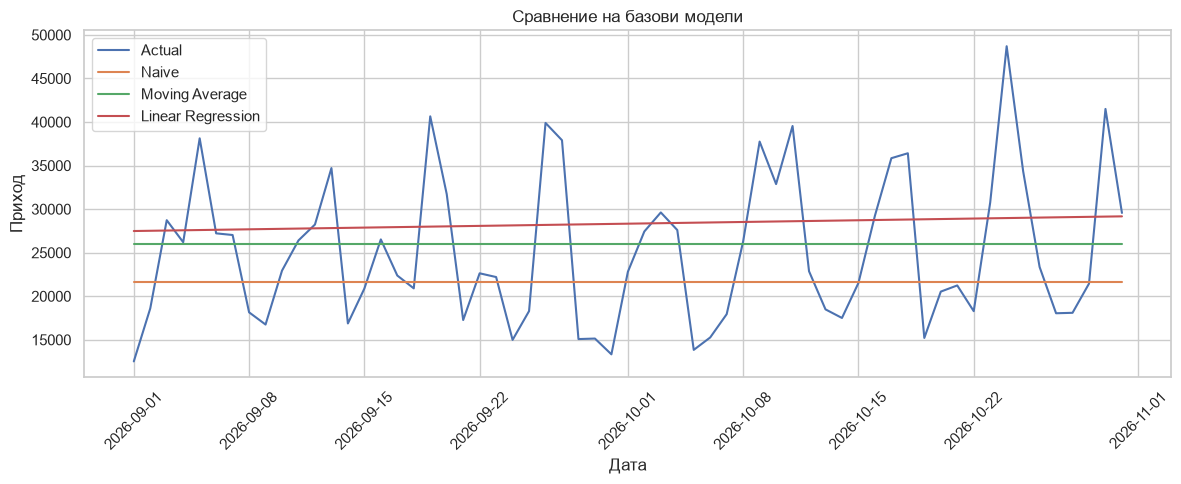

In [120]:
plt.figure(figsize=(12, 5))
plt.plot(test.index, test["Sales"], label="Actual")
plt.plot(test.index, naive_forecast, label="Naive")
plt.plot(test.index, ma_forecast, label="Moving Average")
plt.plot(test.index, linear_forecast, label="Linear Regression")
plt.title("Сравнение на базови модели")
plt.xlabel("Дата")
plt.ylabel("Приход")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.10. Оценка с MAE, MSE и RMSE

In [121]:
models = {
    "Naive": naive_forecast,
    "Moving Average": ma_forecast,
    "Linear Regression": linear_forecast
}

results = []
for name, prediction in models.items():
    mae = mean_absolute_error(test["Sales"], prediction)
    mse = mean_squared_error(test["Sales"], prediction)
    rmse = np.sqrt(mse)
    results.append({"Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse})

results = pd.DataFrame(results)
print(results)

               Model          MAE           MSE         RMSE
0              Naive  7041.393443  8.413792e+07  9172.672506
1     Moving Average  7143.096019  7.196451e+07  8483.189684
2  Linear Regression  7644.946282  8.023924e+07  8957.635775


### 4.11. LSTM

#### Нормализация без data leakage

In [122]:
train_values = train[["Sales"]].values
test_values = test[["Sales"]].values

scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_values)
test_scaled = scaler.transform(test_values)

print("train_scaled:", train_scaled.shape)
print("test_scaled: ", test_scaled.shape)

train_scaled: (304, 1)
test_scaled:  (61, 1)


#### Създаване на последователности

In [123]:
def create_sequences(data, window_size):
    X = []
    y = []
    for i in range(len(data) - window_size):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size])
    return np.array(X), np.array(y)


window_size = 14

X_train_lstm, y_train_lstm = create_sequences(train_scaled, window_size)
print("X_train_lstm:", X_train_lstm.shape)
print("y_train_lstm:", y_train_lstm.shape)

X_train_lstm: (290, 14, 1)
y_train_lstm: (290, 1)


#### Тестови последователности

In [124]:
combined = np.concatenate([
    train_scaled[-window_size:],
    test_scaled
])

X_test_lstm, y_test_lstm = create_sequences(combined, window_size)
print("X_test_lstm:", X_test_lstm.shape)
print("y_test_lstm:", y_test_lstm.shape)

X_test_lstm: (61, 14, 1)
y_test_lstm: (61, 1)


#### Модел

In [125]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# фиксирам началното състояние, за да се повтарят резултатите
tf.keras.utils.set_random_seed(42)

model_lstm = Sequential([
    LSTM(50, input_shape=(window_size, 1)),
    Dense(1)
])

model_lstm.compile(optimizer="adam", loss="mse")
model_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

#### Обучение

Използвам 100 епохи вместо 30, защото при 30 моделът още не е научил седмичния ритъм на продажбите.

In [126]:
history = model_lstm.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=100,
    batch_size=16,
    validation_split=0.1,
    verbose=0
)

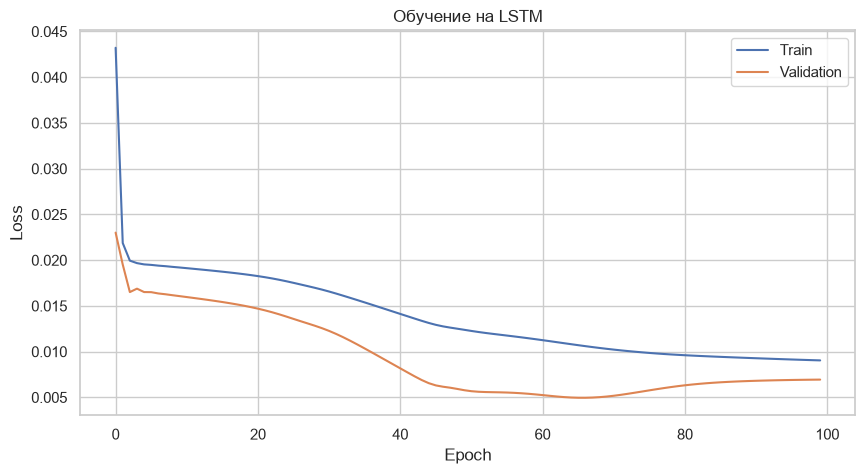

In [127]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.title("Обучение на LSTM")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Train", "Validation"])
plt.show()

#### Прогноза и връщане в оригиналната скала

In [128]:
pred_scaled = model_lstm.predict(X_test_lstm, verbose=0)

predictions = scaler.inverse_transform(pred_scaled)
actual = scaler.inverse_transform(y_test_lstm)

### 4.12. Сравнение на LSTM с базовите модели

LSTM прогнозира само следващия ден по реалните последни 14 дни, а базовите модели дават една прогноза за целия тестов период. Затова сравнението показва колко помага знанието за последните дни.

In [129]:
mae_lstm = mean_absolute_error(actual, predictions)
mse_lstm = mean_squared_error(actual, predictions)
rmse_lstm = np.sqrt(mse_lstm)

results.loc[3] = ["LSTM", mae_lstm, mse_lstm, rmse_lstm]
print(results.sort_values("MAE"))

               Model          MAE           MSE         RMSE
3               LSTM  4991.982854  3.838298e+07  6195.399555
0              Naive  7041.393443  8.413792e+07  9172.672506
1     Moving Average  7143.096019  7.196451e+07  8483.189684
2  Linear Regression  7644.946282  8.023924e+07  8957.635775


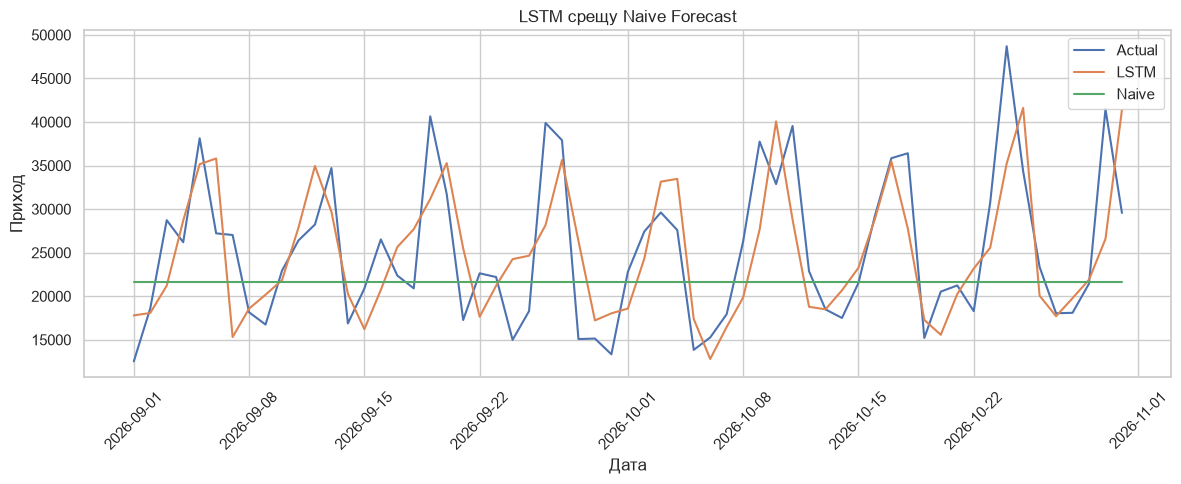

In [130]:
plt.figure(figsize=(12, 5))
plt.plot(test.index, actual, label="Actual")
plt.plot(test.index, predictions, label="LSTM")
plt.plot(test.index, naive_forecast, label="Naive")
plt.title("LSTM срещу Naive Forecast")
plt.xlabel("Дата")
plt.ylabel("Приход")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Етап 5. Анализ на клиентските мнения

### 5.1. Преглед на текстовете

In [131]:
print(reviews.shape)

for text in reviews["ReviewText"].head(5):
    print(text)
    print()

(1434, 7)
I am very satisfied. The customer service was friendly and helpful. I will definitely order again.

@techstore Great purchase. Easy to use and very quiet. Five stars from me.

@techstore Very happy with my order. Easy to use and very quiet. Will buy again.

Really good product. Better than I expected. Totally worth it.

I love this product. Super easy to set up. Good job.



### 5.2. Почистване на текста

Не махам мненията с еднакъв текст, защото са от различни клиенти за различни поръчки. Напълно дублираните редове вече са премахнати в Етап 2.

In [132]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#", "", text)
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

reviews["clean_text"] = reviews["ReviewText"].apply(clean_text)

#### Сравнение преди и след

In [133]:
noisy = reviews[reviews["ReviewText"].str.contains("http|@|#")]

for index in noisy.index[:3]:
    print("Преди:", reviews.loc[index, "ReviewText"])
    print("След: ", reviews.loc[index, "clean_text"])
    print()

Преди: @techstore Great purchase. Easy to use and very quiet. Five stars from me.
След:  great purchase easy to use and very quiet five stars from me

Преди: @techstore Very happy with my order. Easy to use and very quiet. Will buy again.
След:  very happy with my order easy to use and very quiet will buy again

Преди: Perfect, exactly what I wanted. It works perfectly and looks nice. Totally worth it. More photos at https://example.com/reviews
След:  perfect exactly what i wanted it works perfectly and looks nice totally worth it more photos at



### 5.3. Токенизация и stop words

In [134]:
stop_words = set(ENGLISH_STOP_WORDS)

sample = reviews["clean_text"].iloc[0]
tokens = sample.split()
tokens_clean = [w for w in tokens if w not in stop_words]

print("Токени:        ", tokens)
print("Без stop words:", tokens_clean)

Токени:         ['i', 'am', 'very', 'satisfied', 'the', 'customer', 'service', 'was', 'friendly', 'and', 'helpful', 'i', 'will', 'definitely', 'order', 'again']
Без stop words: ['satisfied', 'customer', 'service', 'friendly', 'helpful', 'definitely', 'order']


### 5.4. Честоти на думите с CountVectorizer

In [135]:
vectorizer = CountVectorizer(stop_words="english")
X = vectorizer.fit_transform(reviews["clean_text"])

print("Форма на матрицата:", X.shape)

Форма на матрицата: (1434, 162)


In [136]:
word_counts = X.sum(axis=0).A1

word_freq = pd.DataFrame({
    "word": vectorizer.get_feature_names_out(),
    "frequency": word_counts
}).sort_values("frequency", ascending=False)

print(word_freq.head(20))

            word  frequency
38      delivery        289
92         order        283
106      product        280
108      quality        279
104        price        274
61         great        256
60          good        236
55          fast        232
107     purchase        223
62         happy        194
50      expected        174
112  recommended        163
49     excellent        153
132        store        148
149       vacuum        147
117        robot        147
124      service        145
160        worth        144
46          easy        143
6        arrived        140


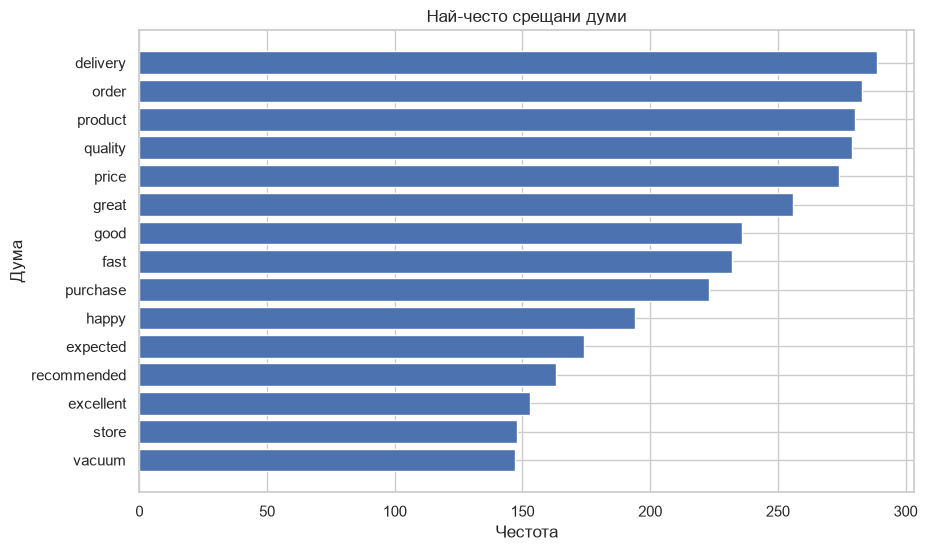

In [137]:
top_words = word_freq.head(15)

plt.figure(figsize=(10, 6))
plt.barh(top_words["word"], top_words["frequency"])
plt.xlabel("Честота")
plt.ylabel("Дума")
plt.title("Най-често срещани думи")
plt.gca().invert_yaxis()
plt.show()

### 5.5. Биграми

In [138]:
bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    stop_words="english"
)
X_bi = bigram_vectorizer.fit_transform(reviews["clean_text"])

bi_counts = X_bi.sum(axis=0).A1

bigrams = pd.DataFrame({
    "ngram": bigram_vectorizer.get_feature_names_out(),
    "frequency": bi_counts
}).sort_values("frequency", ascending=False)

print(bigrams.head(15))

                 ngram  frequency
289        great price        161
220  excellent quality        153
269      fast delivery        152
621       robot vacuum        147
292        happy order        112
112   customer service         99
219     exactly wanted         99
464    perfect exactly         99
290     great purchase         95
47        battery died         93
709        time packed         92
50     better expected         92
18        arrived time         92
286           good job         90
735        value price         87


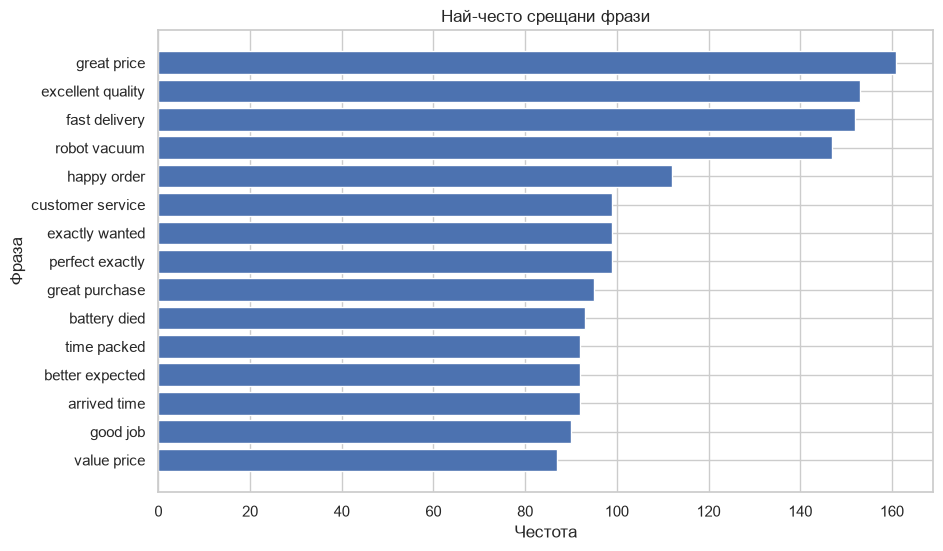

In [139]:
top_bigrams = bigrams.head(15)

plt.figure(figsize=(10, 6))
plt.barh(top_bigrams["ngram"], top_bigrams["frequency"])
plt.xlabel("Честота")
plt.ylabel("Фраза")
plt.title("Най-често срещани фрази")
plt.gca().invert_yaxis()
plt.show()

### 5.6. TF-IDF

In [140]:
tfidf = TfidfVectorizer(stop_words="english")
X_tfidf = tfidf.fit_transform(reviews["clean_text"])

tfidf_scores = X_tfidf.sum(axis=0).A1

tfidf_words = pd.DataFrame({
    "word": tfidf.get_feature_names_out(),
    "score": tfidf_scores
}).sort_values("score", ascending=False)

print(tfidf_words.head(20))

            word      score
108      quality  79.127428
61         great  77.834008
104        price  77.714337
38      delivery  77.677269
92         order  74.703934
106      product  74.614276
60          good  71.658354
55          fast  70.800929
107     purchase  65.538011
62         happy  61.692333
50      expected  56.599557
49     excellent  53.983855
112  recommended  52.239954
132        store  49.457217
46          easy  49.207959
160        worth  49.148479
6        arrived  47.588948
124      service  44.651806
20           buy  44.481178
117        robot  42.770828


### 5.7. Sentiment analysis с VADER

In [141]:
import nltk
nltk.download("vader_lexicon", quiet=True)

from nltk.sentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()

In [142]:
sample_text = reviews["clean_text"].iloc[0]
print("Text:", sample_text)
print("Scores:", sia.polarity_scores(sample_text))

Text: i am very satisfied the customer service was friendly and helpful i will definitely order again
Scores: {'neg': 0.0, 'neu': 0.459, 'pos': 0.541, 'compound': 0.8955}


#### Класификация на всички мнения

In [143]:
def get_sentiment(text):
    compound = sia.polarity_scores(text)["compound"]
    if compound >= 0.05:
        return "Positive"
    elif compound <= -0.05:
        return "Negative"
    else:
        return "Neutral"

reviews["sentiment"] = reviews["clean_text"].apply(get_sentiment)
reviews["compound"] = reviews["clean_text"].apply(
    lambda t: sia.polarity_scores(t)["compound"]
)

print(reviews[["ReviewText", "sentiment", "compound"]].head(10))

                                          ReviewText sentiment  compound
0  I am very satisfied. The customer service was ...  Positive    0.8955
1  @techstore Great purchase. Easy to use and ver...  Positive    0.7906
2  @techstore Very happy with my order. Easy to u...  Positive    0.7841
3  Really good product. Better than I expected. T...  Positive    0.8201
4  I love this product. Super easy to set up. Goo...  Positive    0.9313
5  Awesome store. Great price and excellent quali...  Positive    0.9169
6  Perfect, exactly what I wanted. Better than I ...  Positive    0.7650
7  Perfect, exactly what I wanted. It works perfe...  Positive    0.9168
8  Very happy with my order. Super easy to set up...  Positive    0.9412
9  @techstore I am very satisfied. The courier wa...  Positive    0.8479


### 5.8. Дялове на sentiment категориите

In [144]:
sentiment_counts = reviews["sentiment"].value_counts()
print(sentiment_counts)

sentiment_share = reviews["sentiment"].value_counts(normalize=True) * 100
print(sentiment_share.round(2))

sentiment
Positive    821
Negative    424
Neutral     189
Name: count, dtype: int64
sentiment
Positive    57.25
Negative    29.57
Neutral     13.18
Name: proportion, dtype: float64


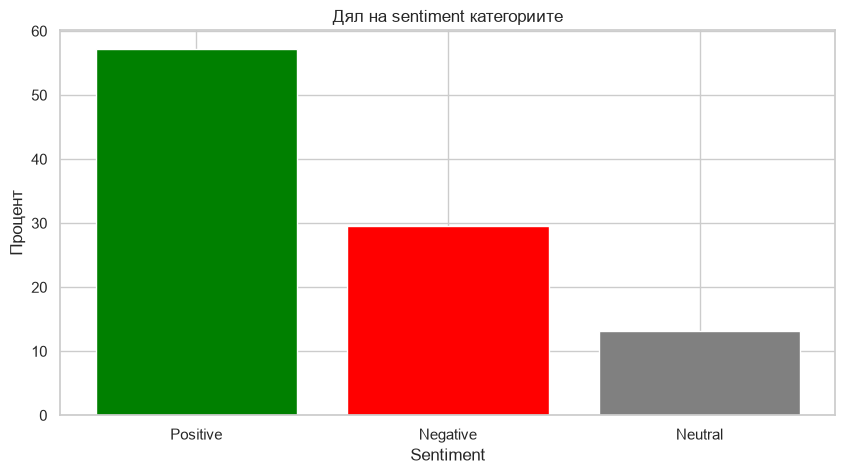

In [145]:
sentiment_colors = {"Positive": "green", "Negative": "red", "Neutral": "gray"}

plt.bar(sentiment_share.index, sentiment_share.values, color=sentiment_share.index.map(sentiment_colors))
plt.title("Дял на sentiment категориите")
plt.xlabel("Sentiment")
plt.ylabel("Процент")
plt.show()

### 5.9. Sentiment и оценка на продукта

Сравнявам автоматичния sentiment с оценката, която клиентът сам е дал.

In [146]:
print(pd.crosstab(reviews["Rating"], reviews["sentiment"]))

sentiment  Negative  Neutral  Positive
Rating                                
1               218        0         9
2               160        0         6
3                46      189         0
4                 0        0       254
5                 0        0       552


### 5.10. Sentiment във времето

In [147]:
reviews["Month"] = reviews["ReviewDate"].dt.to_period("M").astype(str)

monthly_sentiment = pd.crosstab(reviews["Month"], reviews["sentiment"], normalize="index") * 100
print(monthly_sentiment.round(1))

sentiment  Negative  Neutral  Positive
Month                                 
2025-11        13.1     16.4      70.5
2025-12        41.1     11.6      47.3
2026-01         8.0     17.3      74.7
2026-02        22.5     16.9      60.6
2026-03        12.0     15.7      72.3
2026-04        18.5     18.5      63.0
2026-05        19.8     14.2      66.0
2026-06        33.8     12.4      53.8
2026-07        37.9     13.1      49.0
2026-08        31.9     11.7      56.4
2026-09        36.1      7.8      56.0
2026-10        38.6     12.0      49.5
2026-11        43.5     17.4      39.1


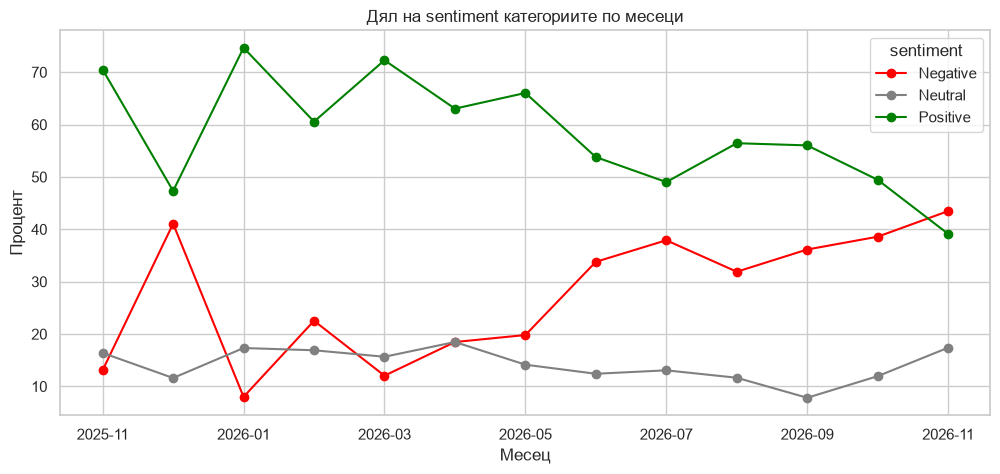

In [148]:
monthly_sentiment.plot(figsize=(12, 5), marker="o", color=sentiment_colors)
plt.title("Дял на sentiment категориите по месеци")
plt.xlabel("Месец")
plt.ylabel("Процент")
plt.show()

Ноември 2026 включва само мненията от първите дни на месеца, затова последната точка е по малко данни.

#### Среден compound по месеци

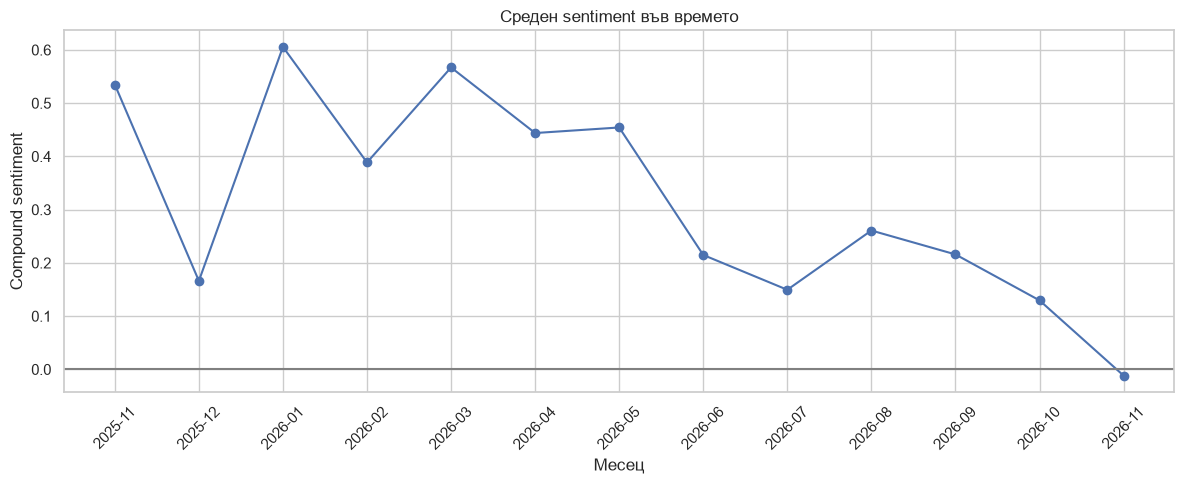

In [149]:
monthly_compound = reviews.groupby("Month")["compound"].mean()

plt.figure(figsize=(12, 5))
plt.plot(monthly_compound.index, monthly_compound.values, marker="o")
plt.axhline(0, color="gray")
plt.title("Среден sentiment във времето")
plt.xlabel("Месец")
plt.ylabel("Compound sentiment")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Най-големи промени

In [150]:
monthly_change = monthly_compound.diff()
print("Най-отрицателни промени:")
print(monthly_change.sort_values().head(3))

Най-отрицателни промени:
Month
2025-12   -0.368696
2026-06   -0.239467
2026-02   -0.217040
Name: compound, dtype: float64


### 5.11. За какво са отрицателните мнения

In [151]:
negative = reviews[reviews["sentiment"] == "Negative"]

negative_vectorizer = CountVectorizer(ngram_range=(2, 2), stop_words="english")
X_negative = negative_vectorizer.fit_transform(negative["clean_text"])

negative_bigrams = pd.DataFrame({
    "ngram": negative_vectorizer.get_feature_names_out(),
    "frequency": X_negative.sum(axis=0).A1
}).sort_values("frequency", ascending=False)

print(negative_bigrams.head(10))

                 ngram  frequency
333       robot vacuum        139
30        battery died         91
393     vacuum stopped         75
370   stopped charging         59
371    stopped working         58
28      bad experience         54
29         bad service         46
174  horrible purchase         44
396         want money         41
397        waste money         39


#### Отрицателни мнения по продукт

In [152]:
reviews_products = reviews.merge(products[["ProductID", "Product", "Category"]], on="ProductID")

product_reviews = reviews_products.groupby("Product").agg(
    Reviews=("ReviewID", "count"),
    MeanRating=("Rating", "mean"),
    MeanCompound=("compound", "mean")
)
product_reviews = product_reviews.sort_values("MeanRating")
print(product_reviews.head(5).round(2))

                     Reviews  MeanRating  MeanCompound
Product                                               
Робот прахосмукачка      324        2.09         -0.39
Климатик                  24        3.58          0.36
Прахосмукачка             45        3.60          0.40
Лаптоп                    14        3.64          0.52
Кафемашина                26        3.73          0.42


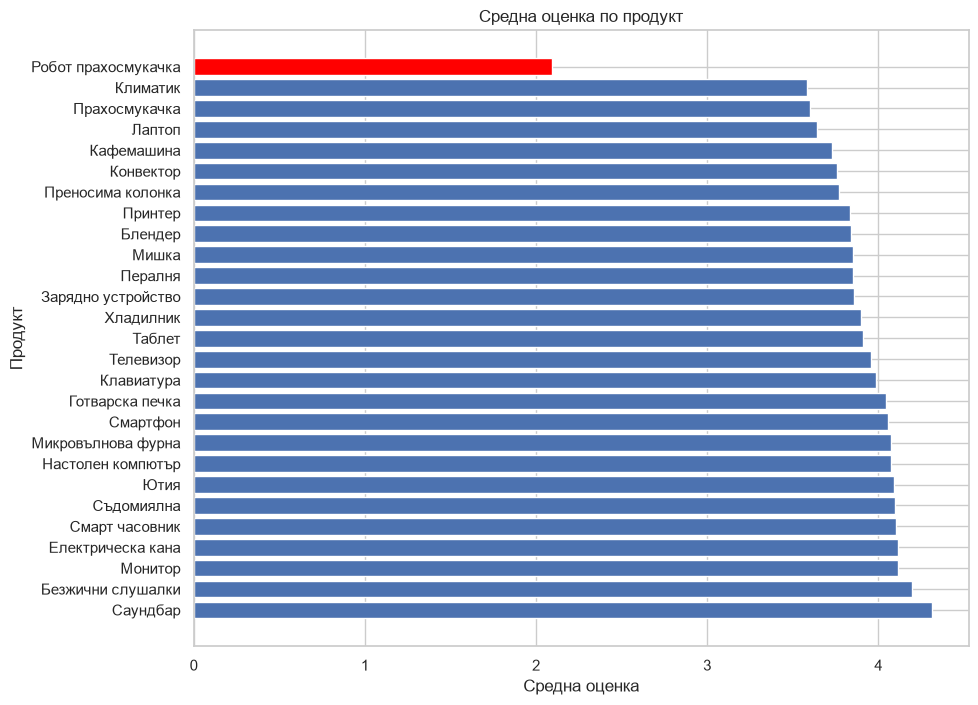

In [153]:
plt.figure(figsize=(10, 8))
# дефектният продукт е в червено
colors = ["red" if product == "Робот прахосмукачка" else "C0" for product in product_reviews.index]

plt.barh(product_reviews.index, product_reviews["MeanRating"], color=colors)
plt.xlabel("Средна оценка")
plt.ylabel("Продукт")
plt.title("Средна оценка по продукт")
plt.gca().invert_yaxis()
plt.show()

#### Робот прахосмукачка преди и след 1 юни 2026

In [154]:
robot_reviews = reviews_products[reviews_products["Product"] == "Робот прахосмукачка"].copy()
robot_reviews["Period"] = "Преди 1 юни"
robot_reviews.loc[robot_reviews["ReviewDate"] >= "2026-06-01", "Period"] = "След 1 юни"

print(robot_reviews.groupby("Period").agg(
    Reviews=("ReviewID", "count"),
    MeanRating=("Rating", "mean"),
    MeanCompound=("compound", "mean")
).round(2))

             Reviews  MeanRating  MeanCompound
Period                                        
Преди 1 юни       39        3.97          0.50
След 1 юни       285        1.84         -0.51


In [155]:
negative_from_june = reviews_products[
    (reviews_products["sentiment"] == "Negative") &
    (reviews_products["ReviewDate"] >= "2026-06-01")
]
robot_share = (negative_from_june["Product"] == "Робот прахосмукачка").mean() * 100
print("Дял на робота в отрицателните мнения от юни:", robot_share)

Дял на робота в отрицателните мнения от юни: 78.33333333333333


#### Мнения през декември

In [156]:
december = negative[negative["Month"] == "2025-12"]
print("Отрицателни мнения през декември:", len(december))
print("От тях за закъсняла доставка:", december["clean_text"].str.contains("late delivery").sum())

Отрицателни мнения през декември: 46
От тях за закъсняла доставка: 34


### 5.12. Интерпретация и ограничения

- Положителните мнения са около 57%, а най-честите фрази са за цена, качество и бърза доставка.
- Има два периода с много отрицателни мнения. През декември те са за закъснели доставки преди празниците. От юни нататък повечето (около 78%) са за един продукт, робота прахосмукачка: батерията спира да работи или да се зарежда.
- Автоматичният sentiment съвпада добре с оценките на клиентите, но не напълно. Част от мненията с оценка 3 са отчетени като отрицателни, а няколко с оценка 1 или 2 като положителни.

Ограничения на автоматичния анализ:

- VADER работи с речник на английски думи и не разбира ирония, сарказъм и контекст. Изречение като "Not what I expected, sadly" може да бъде отчетено различно според отделните думи в него.
- Анализът е само за английски текст. Мнения на български не могат да се обработят със същия речник и stop words.
- Мнение пишат малка част от клиентите и недоволните пишат по-често, така че дяловете не описват всички клиенти.
- Нормализацията е проста: думите не се свеждат до основна форма, затова "stopped" и "stop" се броят отделно.

## Етап 6. Клиентска сегментация и бизнес анализ

### 6.1. Клиентски характеристики (RFM)

Recency е броят дни от последната покупка, Frequency е броят поръчки, Monetary са общите разходи на клиента.

In [157]:
snapshot_date = sales["Date"].max() + pd.Timedelta(days=1)

rfm = sales.groupby("CustomerID").agg(
    Recency=("Date", lambda x: (snapshot_date - x.max()).days),
    Frequency=("OrderID", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()
rfm["AOV"] = rfm["Monetary"] / rfm["Frequency"]

print(rfm.head())

  CustomerID  Recency  Frequency  Monetary      AOV
0      C0001        9         25   6331.45  253.258
1      C0002      108          3   2094.00  698.000
2      C0003       36          5   3298.00  659.600
3      C0004        8         10   3719.00  371.900
4      C0005       49         12   6123.00  510.250


In [158]:
print(rfm.describe())

           Recency    Frequency      Monetary          AOV
count  1946.000000  1946.000000   1946.000000  1946.000000
mean     54.201953     8.232785   4414.368756   530.932853
std      57.894939     7.552440   4312.454786   247.570649
min       1.000000     1.000000     35.000000    35.000000
25%      13.000000     3.000000   1472.500000   367.812500
50%      35.000000     5.000000   2949.000000   505.683333
75%      76.000000    11.000000   5830.500000   649.437500
max     356.000000    45.000000  25855.450000  2277.000000


### 6.2. Стандартизация

In [159]:
rfm_scaler = StandardScaler()
rfm_scaled = rfm_scaler.fit_transform(rfm[["Recency", "Frequency", "Monetary"]])
print(rfm_scaled[:5])

[[-0.78095896  2.22067618  0.4446595 ]
 [ 0.9294746  -0.69303827 -0.53820047]
 [-0.31447708 -0.42815513 -0.25893737]
 [-0.79823606  0.2340527  -0.16128807]
 [-0.08987469  0.49893583  0.39631034]]


### 6.3. Избор на брой клъстери (Elbow метод)

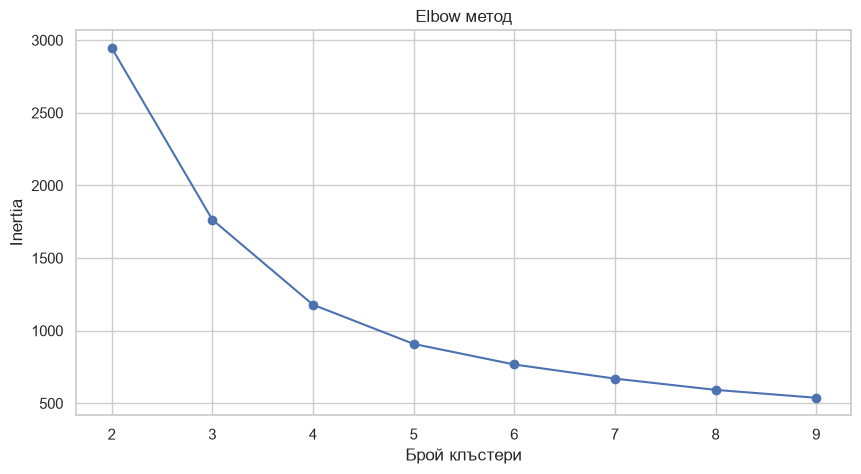

In [160]:
inertias = []
for k in range(2, 10):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(rfm_scaled)
    inertias.append(km.inertia_)

plt.plot(range(2, 10), inertias, marker="o")
plt.title("Elbow метод")
plt.xlabel("Брой клъстери")
plt.ylabel("Inertia")
plt.show()

Кривата се пречупва най-ясно при 3 и 4 клъстера, след това намалението е малко. Избирам 4, защото отделя най-добрите клиенти в собствена група.

### 6.4. K-means

In [161]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)
print(rfm["Cluster"].value_counts())

Cluster
0    1087
3     373
1     369
2     117
Name: count, dtype: int64


### 6.5. Профил на клъстерите

In [162]:
cluster_profile = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary", "AOV"]].mean()
print(cluster_profile.round(2))

         Recency  Frequency  Monetary     AOV
Cluster                                      
0          36.43       4.95   2526.61  519.55
1          20.44      15.44   8490.00  561.92
2          11.78      30.35  16740.55  558.18
3         152.69       3.72   2017.38  524.92


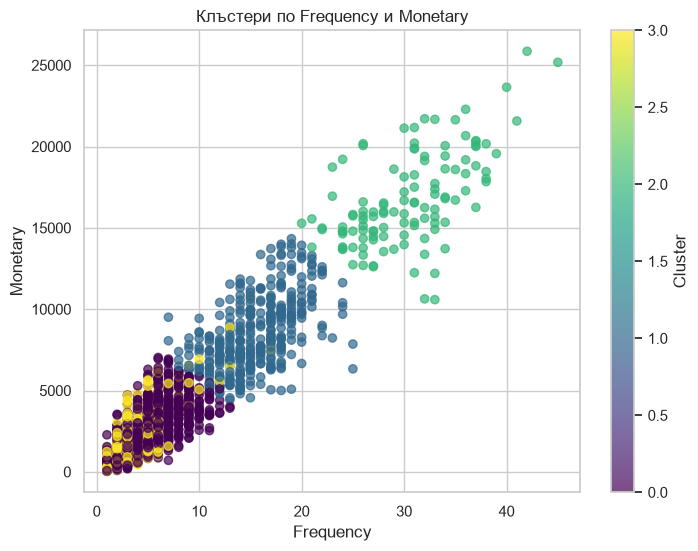

In [163]:
plt.figure(figsize=(8, 6))
plt.scatter(
    rfm["Frequency"], rfm["Monetary"],
    c=rfm["Cluster"], cmap="viridis", alpha=0.7
)
plt.title("Клъстери по Frequency и Monetary")
plt.xlabel("Frequency")
plt.ylabel("Monetary")
plt.colorbar(label="Cluster")
plt.show()

### 6.6. Именуване на сегментите

In [164]:
def name_cluster(row):
    if row["Recency"] > 90:
        return "Неактивни"
    elif row["Frequency"] > 25:
        return "Най-ценни"
    elif row["Frequency"] > 10:
        return "Постоянни"
    else:
        return "Обикновени"

cluster_profile["Segment"] = cluster_profile.apply(name_cluster, axis=1)
print(cluster_profile[["Segment", "Recency", "Frequency", "Monetary"]].round(2))

            Segment  Recency  Frequency  Monetary
Cluster                                          
0        Обикновени    36.43       4.95   2526.61
1         Постоянни    20.44      15.44   8490.00
2         Най-ценни    11.78      30.35  16740.55
3         Неактивни   152.69       3.72   2017.38


In [165]:
rfm["Segment"] = rfm["Cluster"].map(cluster_profile["Segment"])

### 6.7. Разпределение на сегментите

In [166]:
segments = rfm.groupby("Segment").agg(
    Customers=("CustomerID", "count"),
    Revenue=("Monetary", "sum")
)
segments["CustomerShare"] = segments["Customers"] / segments["Customers"].sum() * 100
segments["RevenueShare"] = segments["Revenue"] / segments["Revenue"].sum() * 100

print(segments.sort_values("Revenue", ascending=False).round(2))

            Customers    Revenue  CustomerShare  RevenueShare
Segment                                                      
Постоянни         369  3132811.3          18.96         36.47
Обикновени       1087  2746423.9          55.86         31.97
Най-ценни         117  1958643.9           6.01         22.80
Неактивни         373   752482.5          19.17          8.76


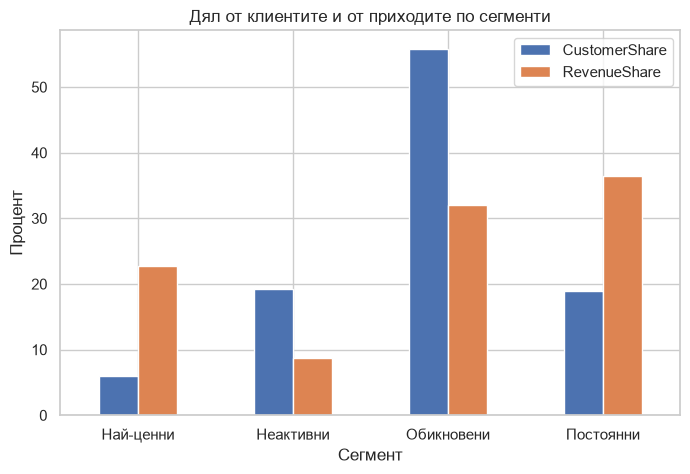

In [167]:
segments[["CustomerShare", "RevenueShare"]].plot(kind="bar", figsize=(8, 5))
plt.title("Дял от клиентите и от приходите по сегменти")
plt.xlabel("Сегмент")
plt.ylabel("Процент")
plt.xticks(rotation=0)
plt.show()

#### Сегменти и клиентска категория

In [168]:
rfm_customers = rfm.merge(customers[["CustomerID", "CustomerCategory"]], on="CustomerID")
print(pd.crosstab(rfm_customers["Segment"], rfm_customers["CustomerCategory"]))

CustomerCategory  VIP  Лоялен  Редовен
Segment                               
Най-ценни         108       9        0
Неактивни           0      14      359
Обикновени         14      97      976
Постоянни          30     313       26


### 6.8. Общи KPI

In [169]:
total_revenue = sales["Revenue"].sum()
total_cost = (sales["Cost"] * sales["Quantity"]).sum()
total_profit = sales["Profit"].sum()
total_orders = sales["OrderID"].nunique()
total_customers = sales["CustomerID"].nunique()
aov = total_revenue / total_orders

print(f"Общ приход:       {total_revenue:,.2f}")
print(f"Себестойност:     {total_cost:,.2f}")
print(f"Обща печалба:     {total_profit:,.2f}")
print(f"Марж на печалбата: {total_profit / total_revenue:.4f}")
print(f"Брой поръчки:     {total_orders}")
print(f"Уникални клиенти: {total_customers}")
print(f"AOV:              {aov:,.2f}")

Общ приход:       8,590,361.60
Себестойност:     6,397,041.00
Обща печалба:     2,193,320.60
Марж на печалбата: 0.2553
Брой поръчки:     16021
Уникални клиенти: 1946
AOV:              536.19


### 6.9. Приходи, себестойност, печалба и марж по категория

In [170]:
sales["TotalCost"] = sales["Cost"] * sales["Quantity"]

by_category = sales.groupby("Category").agg(
    Revenue=("Revenue", "sum"),
    Cost=("TotalCost", "sum"),
    Profit=("Profit", "sum")
)
by_category["Margin"] = by_category["Profit"] / by_category["Revenue"]
by_category = by_category.sort_values("Revenue", ascending=False)

print(by_category.round(2))

                              Revenue     Cost     Profit  Margin
Category                                                         
Малки домакински уреди     2373748.25  1529360  844388.25    0.36
Голяма домакинска техника  2224741.30  1814675  410066.30    0.18
Компютри                   1730677.20  1364298  366379.20    0.21
Телефони и таблети         1344209.60  1000728  343481.60    0.26
Телевизори и аудио          916985.25   687980  229005.25    0.25


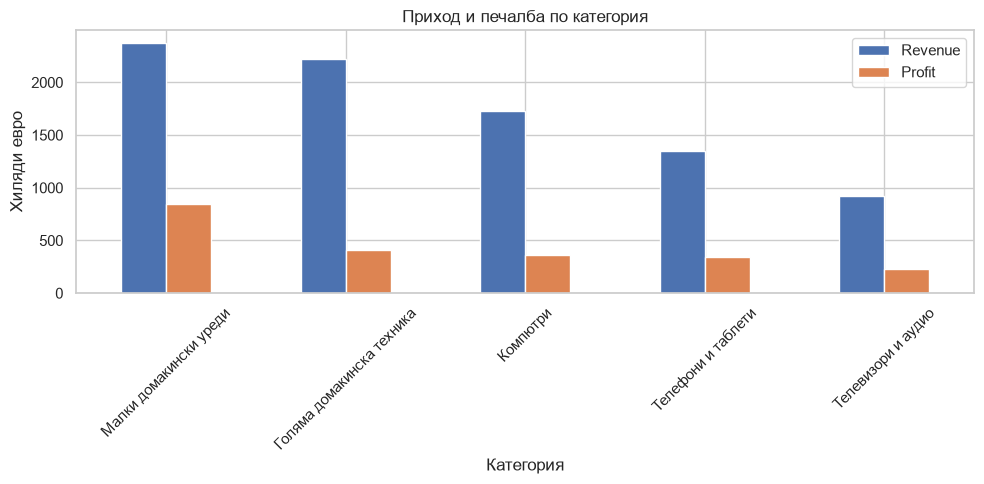

In [171]:
(by_category[["Revenue", "Profit"]] / 1000).plot(kind="bar", figsize=(10, 5))
plt.title("Приход и печалба по категория")
plt.xlabel("Категория")
plt.ylabel("Хиляди евро")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 6.10. Продукти

In [172]:
by_product = sales.groupby("Product").agg(
    Quantity=("Quantity", "sum"),
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum")
)
by_product["Margin"] = by_product["Profit"] / by_product["Revenue"]

print("Топ 10 по приход:")
print(by_product.sort_values("Revenue", ascending=False).head(10).round(2))

Топ 10 по приход:
                     Quantity    Revenue     Profit  Margin
Product                                                    
Робот прахосмукачка      1257  747282.45  206772.45    0.28
Климатик                  551  685388.75  134388.75    0.20
Лаптоп                    282  533808.90   68508.90    0.13
Настолен компютър         288  458353.35   58033.35    0.13
Телевизор                 354  457507.80   71647.80    0.16
Хладилник                 401  437566.85   76666.85    0.18
Конвектор                3297  420862.50  157102.50    0.37
Смартфон                  348  414913.95   52993.95    0.13
Пералня                   452  381583.05   69703.05    0.18
Съдомиялна                423  377984.55   67079.55    0.18


In [173]:
print("Топ 5 по марж:")
print(by_product.sort_values("Margin", ascending=False).head(5).round(2))

Топ 5 по марж:
                    Quantity    Revenue    Profit  Margin
Product                                                  
Зарядно устройство      3542  123313.75  73725.75    0.60
Мишка                   3478  134770.35  68688.35    0.51
Електрическа кана       2852  139042.40  70594.40    0.51
Блендер                 2143  189538.85  86674.85    0.46
Клавиатура              2552  175135.80  78159.80    0.45


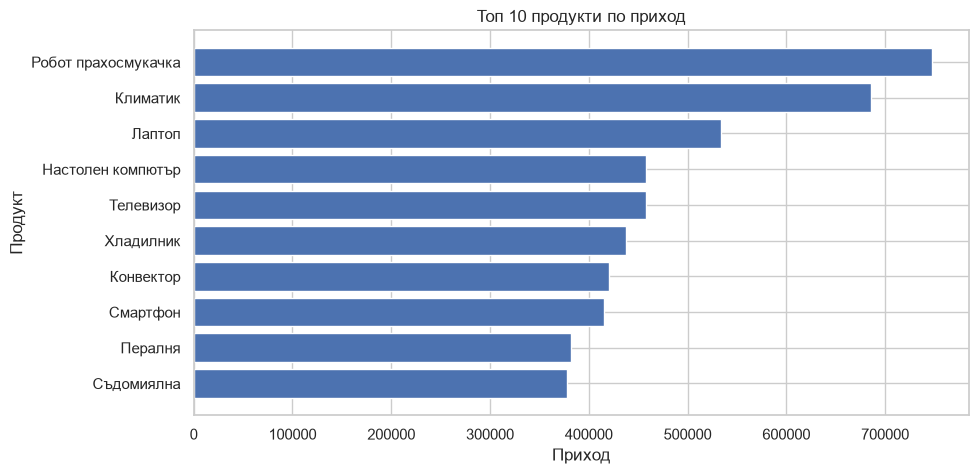

In [174]:
top_products = by_product.sort_values("Revenue", ascending=False).head(10)

plt.figure(figsize=(10, 5))
plt.barh(top_products.index, top_products["Revenue"])
plt.title("Топ 10 продукти по приход")
plt.xlabel("Приход")
plt.ylabel("Продукт")
plt.gca().invert_yaxis()
plt.show()

### 6.11. Месечни приходи и процентен ръст

In [175]:
sales["Month"] = sales["Date"].dt.to_period("M").astype(str)

monthly = sales.groupby("Month").agg(
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum"),
    Orders=("OrderID", "nunique")
)
monthly["Margin"] = monthly["Profit"] / monthly["Revenue"]
monthly["Growth"] = monthly["Revenue"].pct_change() * 100

print(monthly.round(2))

          Revenue    Profit  Orders  Margin  Growth
Month                                              
2025-11  696967.6  149768.6    1433    0.21     NaN
2025-12  762068.0  202555.0    1422    0.27    9.34
2026-01  427549.0  114194.0     871    0.27  -43.90
2026-02  562186.0  150393.0    1073    0.27   31.49
2026-03  665430.0  174560.0    1220    0.26   18.36
2026-04  706194.0  180737.0    1240    0.26    6.13
2026-05  716968.0  188445.0    1389    0.26    1.53
2026-06  797453.0  197437.0    1370    0.25   11.23
2026-07  855982.0  214262.0    1495    0.25    7.34
2026-08  863375.0  220014.0    1556    0.25    0.86
2026-09  722269.0  187135.0    1375    0.26  -16.34
2026-10  813920.0  213820.0    1577    0.26   12.69


#### Сравними периоди: първа и втора половина на годината

In [176]:
middle_date = sales["Date"].min() + (sales["Date"].max() - sales["Date"].min()) / 2
print("Среда на периода:", middle_date)

first_half = sales[sales["Date"] <= middle_date]["Revenue"].sum()
second_half = sales[sales["Date"] > middle_date]["Revenue"].sum()
growth = (second_half - first_half) / first_half * 100

print(f"Първа половина: {first_half:,.2f}")
print(f"Втора половина: {second_half:,.2f}")
print(f"Ръст:           {growth:.2f}%")

Среда на периода: 2026-05-02 00:00:00
Първа половина: 3,876,298.60
Втора половина: 4,714,063.00
Ръст:           21.61%


### 6.12. Сезонни продукти

In [177]:
seasonal = sales[sales["Product"].isin(["Климатик", "Конвектор"])]
seasonal_by_month = pd.crosstab(
    seasonal["Month"], seasonal["Product"],
    values=seasonal["Quantity"], aggfunc="sum"
)
print(seasonal_by_month)

Product  Климатик  Конвектор
Month                       
2025-11        28        544
2025-12        23        599
2026-01        16        345
2026-02        32        417
2026-03        24        142
2026-04        30        158
2026-05        20        164
2026-06        85        179
2026-07       110        183
2026-08       107        182
2026-09        31        179
2026-10        45        205


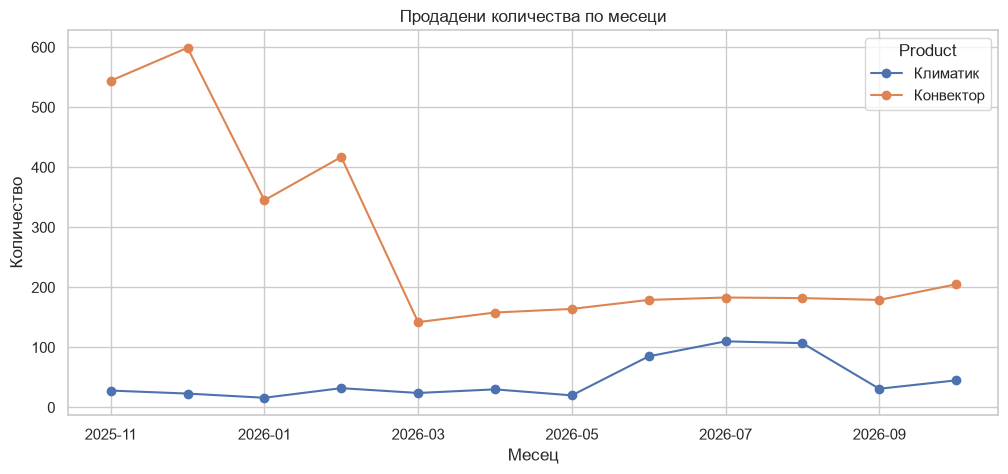

In [178]:
seasonal_by_month.plot(figsize=(12, 5), marker="o")
plt.title("Продадени количества по месеци")
plt.xlabel("Месец")
plt.ylabel("Количество")
plt.show()

### 6.13. Клиентско поведение

#### Статус на поръчката по начин на плащане

In [179]:
status_by_payment = pd.crosstab(orders["PaymentMethod"], orders["Status"], normalize="index") * 100
print(status_by_payment.round(2))

Status          Върната  Доставена  Отказана
PaymentMethod                               
Банков превод      3.02      94.31      2.67
Карта              2.71      94.06      3.22
Наложен платеж     2.45      79.78     17.77
Неизвестен         1.67      90.00      8.33


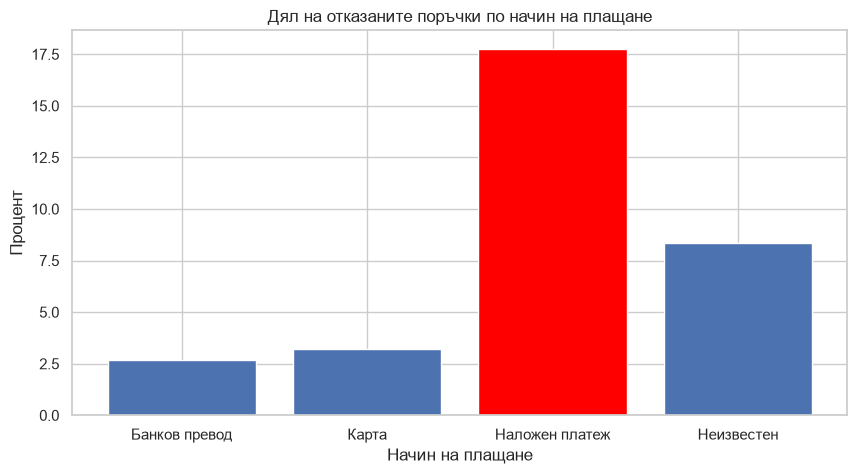

In [180]:
colors = ["red" if payment == "Наложен платеж" else "C0" for payment in status_by_payment.index]

plt.bar(status_by_payment.index, status_by_payment["Отказана"], color=colors)
plt.title("Дял на отказаните поръчки по начин на плащане")
plt.xlabel("Начин на плащане")
plt.ylabel("Процент")
plt.show()

#### Върнати поръчки по продукт

In [181]:
received = order_lines[order_lines["Status"] != "Отказана"].copy()
received["Returned"] = received["Status"] == "Върната"

returns_by_product = received.groupby("Product")["Returned"].mean() * 100
top_returns = returns_by_product.sort_values(ascending=False).head(5)
print(top_returns.round(2))

Product
Робот прахосмукачка    16.92
Преносима колонка       2.99
Готварска печка         2.96
Смарт часовник          2.87
Таблет                  2.86
Name: Returned, dtype: float64


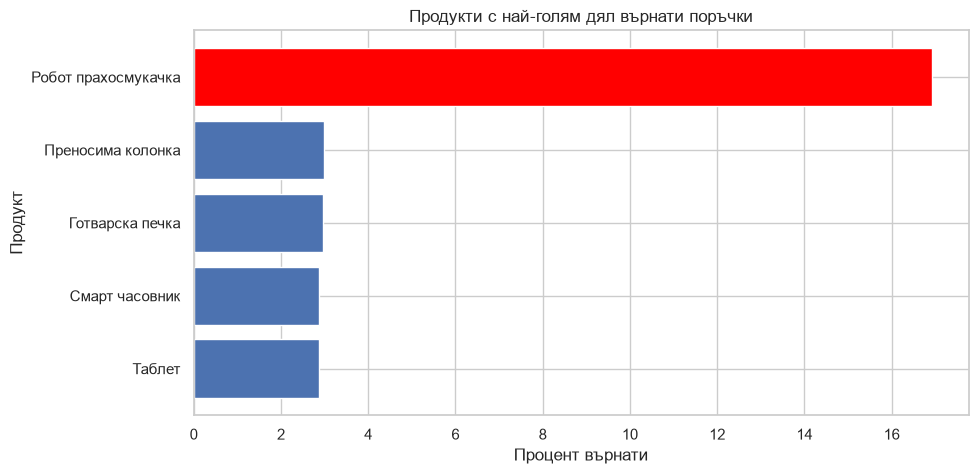

In [182]:
colors = ["red" if product == "Робот прахосмукачка" else "C0" for product in top_returns.index]

plt.barh(top_returns.index, top_returns.values, color=colors)
plt.title("Продукти с най-голям дял върнати поръчки")
plt.xlabel("Процент върнати")
plt.ylabel("Продукт")
plt.gca().invert_yaxis()
plt.show()

In [183]:
robot_orders = received[received["Product"] == "Робот прахосмукачка"].copy()
robot_orders["Period"] = "Преди 1 юни"
robot_orders.loc[robot_orders["Date"] >= "2026-06-01", "Period"] = "След 1 юни"

print(robot_orders.groupby("Period")["Returned"].mean() * 100)

Period
Преди 1 юни     1.618929
След 1 юни     34.225352
Name: Returned, dtype: float64


## Етап 7. Интерактивно табло

Таблото е в отделен файл `dashboard.py` и е направено със Streamlit и Plotly. Тук записвам в папката `data` подготвените данни, които то зарежда.

### 7.1. Продажби със сегмент на клиента

In [184]:
dashboard_sales = sales.merge(rfm[["CustomerID", "Segment"]], on="CustomerID")
dashboard_sales = dashboard_sales[[
    "OrderID", "Date", "CustomerID", "Segment",
    "Product", "Category", "Quantity", "Revenue", "Profit"
]]

dashboard_sales.to_csv("data/dashboard_sales.csv", index=False)
print(dashboard_sales.head())

   OrderID       Date CustomerID     Segment              Product  \
0    10001 2025-11-01      C1501   Постоянни    Безжични слушалки   
1    10002 2025-11-01      C0119   Неактивни            Конвектор   
2    10003 2025-11-01      C1774  Обикновени               Таблет   
3    10005 2025-11-01      C0698   Постоянни           Клавиатура   
4    10006 2025-11-01      C1949   Постоянни  Робот прахосмукачка   

                 Category  Quantity  Revenue  Profit  
0      Телефони и таблети         2    298.0   128.0  
1  Малки домакински уреди         1    129.0    49.0  
2      Телефони и таблети         1    649.0   104.0  
3                Компютри         3    207.0    93.0  
4  Малки домакински уреди         1    599.0   169.0  


### 7.2. Мнения със sentiment

In [185]:
dashboard_reviews = reviews_products.merge(rfm[["CustomerID", "Segment"]], on="CustomerID")
dashboard_reviews = dashboard_reviews[[
    "ReviewID", "ReviewDate", "Segment", "Product", "Category", "Rating", "sentiment", "compound"
]]

dashboard_reviews.to_csv("data/dashboard_reviews.csv", index=False)
print(dashboard_reviews.head())

   ReviewID ReviewDate     Segment             Product  \
0         1 2025-11-05   Най-ценни            Саундбар   
1         2 2025-11-05   Най-ценни             Блендер   
2         3 2025-11-04  Обикновени   Електрическа кана   
3         4 2025-11-05   Неактивни          Клавиатура   
4         5 2025-11-09   Постоянни  Зарядно устройство   

                 Category  Rating sentiment  compound  
0      Телевизори и аудио       5  Positive    0.8955  
1  Малки домакински уреди       4  Positive    0.7906  
2  Малки домакински уреди       5  Positive    0.7841  
3                Компютри       5  Positive    0.8201  
4      Телефони и таблети       5  Positive    0.9313  


### 7.3. Реални и прогнозирани продажби

In [186]:
dashboard_forecast = pd.DataFrame({"Actual": df["Sales"]})
dashboard_forecast.loc[test.index, "Linear Regression"] = linear_forecast
dashboard_forecast.loc[test.index, "LSTM"] = predictions.flatten()

dashboard_forecast.to_csv("data/dashboard_forecast.csv")
print(dashboard_forecast.tail())

             Actual  Linear Regression          LSTM
Date                                                
2026-10-27  18044.0       29056.718563  17706.816406
2026-10-28  18096.0       29084.786685  19777.078125
2026-10-29  21449.0       29112.854807  21902.031250
2026-10-30  41499.0       29140.922929  26575.998047
2026-10-31  29563.0       29168.991051  41411.726562


### 7.4. Стартиране на таблото

В терминала на PyCharm, в папката на проекта:

`streamlit run dashboard.py`

## Етап 8. Изводи и бизнес препоръки

Изводите са направени по два начина: с езиков модел (LLM) по примера от лекциите и самостоятелно. Моделът не смята нищо сам. Той получава само показателите, изчислени в предишните етапи.

### 8.1. Показатели, които се подават към модела

Освен общите показатели подавам месечното изменение на прихода, продажбите на климатици, приходите по дни от седмицата, отрицателните мнения през декември и дела на робота в отрицателните мнения от юни. Без тях моделът не вижда спадовете през януари и септември и смята, че всички отрицателни мнения са за робота.

In [187]:
stats = {}

stats["period"] = "2025-11-01 до 2026-10-31"
stats["total_revenue"] = round(total_revenue, 2)
stats["total_profit"] = round(total_profit, 2)
stats["profit_margin_percent"] = round(total_profit / total_revenue * 100, 2)
stats["orders"] = total_orders
stats["customers"] = total_customers
stats["average_order_value"] = round(aov, 2)
stats["revenue_growth_percent"] = round(growth, 2)

stats["by_category"] = by_category.round(2).to_dict("index")
stats["top_products_by_revenue"] = by_product.sort_values("Revenue", ascending=False).head(5).round(2).to_dict("index")
stats["monthly_revenue"] = monthly["Revenue"].round(2).to_dict()
stats["monthly_revenue_change_percent"] = monthly["Growth"].dropna().round(2).to_dict()
stats["air_conditioners_sold_by_month"] = seasonal_by_month["Климатик"].to_dict()
weekday_names = ["понеделник", "вторник", "сряда", "четвъртък", "петък", "събота", "неделя"]
stats["average_revenue_by_weekday"] = dict(zip(weekday_names, weekly["Sales"].round(2)))
stats["customer_segments"] = segments.round(2).to_dict("index")

In [188]:
stats["cancelled_percent_total"] = round((orders["Status"] == "Отказана").mean() * 100, 2)
stats["cancelled_percent_by_payment"] = status_by_payment["Отказана"].round(2).to_dict()
stats["returned_percent_by_product"] = top_returns.round(2).to_dict()
stats["robot_returned_percent_by_period"] = (robot_orders.groupby("Period")["Returned"].mean() * 100).round(2).to_dict()
stats["robot_rating_by_period"] = robot_reviews.groupby("Period")["Rating"].mean().round(2).to_dict()

stats["sentiment_percent"] = sentiment_share.round(2).to_dict()
stats["negative_percent_by_month"] = monthly_sentiment["Negative"].round(2).to_dict()
stats["top_negative_phrases"] = negative_bigrams.head(8).set_index("ngram")["frequency"].to_dict()
stats["robot_share_of_negative_from_june_percent"] = round(robot_share, 2)
stats["december_negative_reviews"] = len(december)
stats["december_late_delivery_reviews"] = int(december["clean_text"].str.contains("late delivery").sum())
stats["lowest_rated_products"] = product_reviews["MeanRating"].head(3).round(2).to_dict()

stats["forecast_mae_by_model"] = results.set_index("Model")["MAE"].round(2).to_dict()

In [189]:
stats_json = json.dumps(stats, indent=2, ensure_ascii=False)
print(stats_json)

{
  "period": "2025-11-01 до 2026-10-31",
  "total_revenue": 8590361.6,
  "total_profit": 2193320.6,
  "profit_margin_percent": 25.53,
  "orders": 16021,
  "customers": 1946,
  "average_order_value": 536.19,
  "revenue_growth_percent": 21.61,
  "by_category": {
    "Малки домакински уреди": {
      "Revenue": 2373748.25,
      "Cost": 1529360,
      "Profit": 844388.25,
      "Margin": 0.36
    },
    "Голяма домакинска техника": {
      "Revenue": 2224741.3,
      "Cost": 1814675,
      "Profit": 410066.3,
      "Margin": 0.18
    },
    "Компютри": {
      "Revenue": 1730677.2,
      "Cost": 1364298,
      "Profit": 366379.2,
      "Margin": 0.21
    },
    "Телефони и таблети": {
      "Revenue": 1344209.6,
      "Cost": 1000728,
      "Profit": 343481.6,
      "Margin": 0.26
    },
    "Телевизори и аудио": {
      "Revenue": 916985.25,
      "Cost": 687980,
      "Profit": 229005.25,
      "Margin": 0.25
    }
  },
  "top_products_by_revenue": {
    "Робот прахосмукачка": {
      

### 8.2. Prompt

Системният prompt казва на модела кой е, за кого пише и как да пише. Вместо сух отчет по точки моделът трябва сам да открие историите в данните: промени и контрасти, които се виждат в числата. Всяка история има заглавие, какво се случва, кои числа го показват и какво да се направи. Потребителският prompt е разделен на пет части: контекст, показатели, значение на полетата, задача и правила. Спрямо примера от лекциите той е разширен, защото при предишните опити моделът бъркаше точно там, където не му беше обяснено: наричаше нисък марж, който е над средния, правеше изводи по непълен месец и обясняваше всички отрицателни мнения с робота.

In [190]:
system_prompt = (
    "Ти си бизнес анализатор на онлайн магазин за електроника и техника за дома. "
    "Пишеш за управителя на магазина и твоята задача е да му покажеш какво се крие зад числата. "
    "Пишеш като добър журналист, който работи с данни: всяка история има заглавие, ясен сюжет и числа, които я доказват. "
    "Тонът е жив и интересен, но без преувеличения, клишета и празни фрази. "
    "Пишеш на правилен български език. "
    "Използваш само числата, които получаваш. Не измисляш числа, а когато причината за нещо не се вижда в данните, казваш го. "
    "Пиши само обикновен текст, без markdown: без звездички, диезове, таблици и удебелен шрифт."
)

In [191]:
user_prompt = f"""
КОНТЕКСТ
Онлайн магазин в България продава електроника и техника за дома.
Показателите са изчислени с Python от поръчките, клиентите и клиентските мнения за периода {stats["period"]}.
Всички суми са в евро, а дяловете са в проценти.

ПОКАЗАТЕЛИ
{stats_json}

ЗНАЧЕНИЕ НА ПОЛЕТАТА
- Margin: марж на печалбата като дял от 0 до 1 (0.36 означава 36%). Средният марж на магазина е profit_margin_percent.
- revenue_growth_percent: изменение на прихода през втората половина на периода спрямо първата. Не е годишен растеж.
- monthly_revenue_change_percent: изменение на прихода спрямо предходния месец. Отрицателното число е спад.
- air_conditioners_sold_by_month: брой продадени климатици по месеци.
- average_revenue_by_weekday: среден дневен приход за всеки ден от седмицата.
- customer_segments: клиентски сегменти от K-means по RFM. CustomerShare и RevenueShare са дял от клиентите и дял от приходите.
- cancelled_percent_total: дял на отказаните поръчки от всички поръчки.
- cancelled_percent_by_payment: за всеки начин на плащане какъв дял от поръчките с него са отказани. "Неизвестен" не е начин на плащане, а поръчки, при които той липсва в данните.
- returned_percent_by_product: дял на върнатите поръчки по продукт.
- robot_returned_percent_by_period и robot_rating_by_period: дял на върнатите поръчки и средна оценка (от 1 до 5) за продукта Робот прахосмукачка преди и след 1 юни 2026.
- negative_percent_by_month: дял на отрицателните мнения по месеци. Месец 2026-11 е непълен, не прави изводи по него.
- top_negative_phrases: най-честите фрази в отрицателните мнения за целия период (мненията са на английски).
- robot_share_of_negative_from_june_percent: каква част от отрицателните мнения от 1 юни 2026 нататък са за Робот прахосмукачка.
- december_negative_reviews и december_late_delivery_reviews: брой отрицателни мнения през декември 2025 и колко от тях са за закъсняла доставка.
- lowest_rated_products: продуктите с най-ниска средна оценка по скала от 1 до 5.
- forecast_mae_by_model: средна абсолютна грешка на прогнозата на дневния приход в евро. LSTM прогнозира само следващия ден, а другите модели целия тестов период наведнъж, затова сравнението не е напълно равностойно.

ЗАДАЧА
Открий най-интересните истории в показателите, обикновено пет или шест. История е промяна или контраст, който се вижда в числата: нещо, което се променя от определен месец, нещо, което се повтаря всяка седмица или сезон, малка група, която носи голяма част от прихода. Не изреждай показателите един по един и не пиши за неща, в които няма история.

Започни с две изречения за общата картина на магазина.
След това за всяка история напиши:
- кратко заглавие, което звучи като заглавие на статия;
- три или четири изречения: какво се случва, от кога и кои числа го показват;
- едно изречение какво трябва да направи магазинът.
Подреди историите от най-спешната към най-малко спешната. Накрая с едно изречение кажи с коя история управителят трябва да започне утре и защо.

ПРАВИЛА
- Вплитай числата в текста, така че всяко твърдение да може да се провери.
- Когато наричаш нещо високо или ниско, сравни го с нещо от показателите, например маржа със средния марж на магазина.
- Когато обясняваш промяна, потърси подкрепа в другите показатели. Ако няма такава, напиши, че причината не се вижда в данните.
- Когато даваш диапазон за няколко месеца, провери всички месеци и вземи най-ниската и най-високата стойност.
- Не наричай растежа устойчив, защото в някои месеци приходът пада.
- Не пиши имената на полетата от показателите, а ги казвай с думи.
- Отговорът да е до 500 думи.
"""

### 8.3. Заявка към Claude API

В лекциите заявката е към OpenRouter. При пробите с безплатните модели там анализът имаше езикови грешки и грешни тълкувания, затова използвам Claude API. Кодът е същият по структура (`requests.post` с `headers` и `payload`), сменят се само адресът, хедърите и мястото на текста в отговора. Ключът се чете от файла `claude_key.txt`, за да не стои в кода.

In [192]:
CLAUDE_API_KEY = ""
if os.path.exists("claude_key.txt"):
    CLAUDE_API_KEY = open("claude_key.txt").read().strip()

MODEL = "claude-opus-5-5"

In [193]:
def ask_llm_for_business_analysis(system_prompt, user_prompt):
    headers = {
        "x-api-key": CLAUDE_API_KEY,
        "anthropic-version": "2023-06-01",
        "Content-Type": "application/json"
    }

    payload = {
        "model": MODEL,
        "system": system_prompt,
        "messages": [
            {"role": "user", "content": user_prompt}
        ],
        "max_tokens": 16000
    }

    try:
        response = requests.post(
            "https://api.anthropic.com/v1/messages",
            headers=headers,
            data=json.dumps(payload),
            timeout=180
        )
        response.raise_for_status()
        result = response.json()

        # отговорът е списък от блокове, текстът на анализа е в блока от тип "text"
        for block in result["content"]:
            if block["type"] == "text":
                return block["text"]
        return "В отговора няма текст."

    except requests.exceptions.RequestException as e:
        return f"Грешка при връзка с Claude API: {e}"
    except KeyError as e:
        return f"Неочакван формат на отговора от API: {e}"

### 8.4. Бизнес анализ от езиковия модел

In [194]:
if CLAUDE_API_KEY == "":
    analysis = "Няма API ключ. Запишете ключа от Claude Console във файл claude_key.txt в папката на проекта."
else:
    analysis = ask_llm_for_business_analysis(system_prompt, user_prompt)

print(analysis)

Магазинът е продал за 8 590 361,60 евро и е спечелил 2 193 320,60 евро, което е марж от 25,53%, от 16 021 поръчки на 1946 клиенти. Втората половина на периода носи с 21,61% повече приход от първата, но растежът не е равномерен: през януари приходът пада с 43,9%, а през септември с 16,34%.

Хитовият продукт се превърна в най-големия проблем

Робот прахосмукачката е най-продаваният продукт по приход (747 282,45 евро) и има марж 28%, над средния за магазина. След 1 юни обаче делът на върнатите поръчки за нея скача от 1,62% на 34,23%, а средната ѝ оценка пада от 3,97 на 1,84. От юни насам 78,33% от отрицателните мнения са за нея, а сред най-честите оплаквания са „battery died“ (91 пъти) и „stopped charging“ (59 пъти). Данните сочат проблем с батерията и зареждането, но дали причината е нова партида или нов доставчик, не се вижда.
Магазинът трябва веднага да спре продажбите на модела и да провери с доставчика партидите, доставени след юни.

Всяка шеста поръчка с наложен платеж се отказва

С

### 8.5. Проверка на генерирания анализ

Към модела се подават само обобщените показатели от 8.1. Сверих числата в анализа с тях и всички съвпадат, а шестте истории са точно тези, които се виждат в данните: робота, наложения платеж, декември, климатиците, клиентските групи и ниския марж на голямата техника. Моделът не измисля причини, а където не може да ги види (дали дефектът е от нова партида или от нов доставчик), казва това; единственото отклонение е дължината, около 530 думи при зададени до 500.

### 8.6. Интерпретация на етапи 3, 4, 5 и 6 от Claude

Освен общия анализ давам на Claude и резултатите от статистическия анализ, времевите серии, клиентските мнения и сегментацията, за да напише интерпретация за всеки етап. След това я сравнявам с моите интерпретации в 3.13, 4.7, 4.12, 5.12 и 6.3.

In [195]:
stage_results = {}

stage_results["stage3_pearson_correlation"] = correlation_matrix.round(2).to_dict()
stage_results["stage3_spearman_correlation"] = spearman_matrix.round(2).to_dict()
stage_results["stage3_price_and_quantity"] = {
    "pearson_r": round(pearson_r, 2), "pearson_p": round(pearson_p, 4),
    "spearman_rho": round(spearman_rho, 2), "spearman_p": round(spearman_p, 4)
}
stage_results["stage3_orders_and_revenue_per_customer"] = {
    "pearson_r": round(r_orders, 2), "pearson_p": round(p_orders, 4),
    "spearman_rho": round(rho_orders, 2), "spearman_p": round(p_orders_s, 4)
}
stage_results["stage3_age_and_revenue_per_customer"] = {
    "pearson_r": round(r_age, 2), "pearson_p": round(p_age, 4),
    "spearman_rho": round(rho_age, 2), "spearman_p": round(p_age_s, 4)
}

In [196]:
stage_results["stage4_period"] = {
    "first_day": str(df.index.min().date()),
    "last_day": str(df.index.max().date()),
    "test_from": split_date,
    "test_days": len(test)
}
stage_results["stage4_average_revenue_by_weekday"] = dict(zip(weekday_names, weekly["Sales"].round(2)))
stage_results["stage4_average_orders_by_weekday"] = dict(zip(weekday_names, weekly["Orders"].round(1)))
stage_results["stage4_monthly_revenue_and_orders"] = monthly_sales.set_index(monthly_sales.index.strftime("%Y-%m")).round(0).to_dict("index")
stage_results["stage4_linear_regression_slope_per_day"] = round(model_lr.coef_[0], 2)
stage_results["stage4_average_daily_revenue_in_test"] = round(test["Sales"].mean(), 2)
stage_results["stage4_forecast_errors"] = results.set_index("Model").round(2).to_dict("index")
stage_results["stage4_lstm_setup"] = "LSTM прогнозира само следващия ден по реалните приходи от последните 14 дни. Базовите модели дават една прогноза за целия тестов период."

In [197]:
stage_results["stage5_method"] = "VADER върху мнения на английски. Мнението е Positive при compound от 0.05 нагоре и Negative при compound до -0.05."
stage_results["stage5_sentiment_percent"] = sentiment_share.round(2).to_dict()
stage_results["stage5_sentiment_by_rating"] = pd.crosstab(reviews["Rating"], reviews["sentiment"]).to_dict("index")
stage_results["stage5_negative_percent_by_month"] = monthly_sentiment["Negative"].round(2).to_dict()
stage_results["stage5_top_negative_phrases"] = negative_bigrams.head(8).set_index("ngram")["frequency"].to_dict()
stage_results["stage5_robot_share_of_negative_from_june_percent"] = round(robot_share, 2)
stage_results["stage5_december_negative_reviews"] = len(december)
stage_results["stage5_december_late_delivery_reviews"] = int(december["clean_text"].str.contains("late delivery").sum())

In [198]:
stage_results["stage6_inertia_by_number_of_clusters"] = dict(zip(range(2, 10), [round(x, 1) for x in inertias]))
stage_results["stage6_chosen_number_of_clusters"] = 4
stage_results["stage6_cluster_profile"] = cluster_profile.round(2).set_index("Segment").to_dict("index")
stage_results["stage6_segments"] = segments.round(2).to_dict("index")
stage_results["stage6_segment_by_customer_category"] = pd.crosstab(rfm_customers["Segment"], rfm_customers["CustomerCategory"]).to_dict("index")

stage_results_json = json.dumps(stage_results, indent=2, ensure_ascii=False)
print(stage_results_json)

{
  "stage3_pearson_correlation": {
    "Quantity": {
      "Quantity": 1.0,
      "UnitPrice": -0.38,
      "Cost": -0.37,
      "Revenue": -0.25,
      "Profit": -0.01
    },
    "UnitPrice": {
      "Quantity": -0.38,
      "UnitPrice": 1.0,
      "Cost": 1.0,
      "Revenue": 0.98,
      "Profit": 0.81
    },
    "Cost": {
      "Quantity": -0.37,
      "UnitPrice": 1.0,
      "Cost": 1.0,
      "Revenue": 0.98,
      "Profit": 0.78
    },
    "Revenue": {
      "Quantity": -0.25,
      "UnitPrice": 0.98,
      "Cost": 0.98,
      "Revenue": 1.0,
      "Profit": 0.87
    },
    "Profit": {
      "Quantity": -0.01,
      "UnitPrice": 0.81,
      "Cost": 0.78,
      "Revenue": 0.87,
      "Profit": 1.0
    }
  },
  "stage3_spearman_correlation": {
    "Quantity": {
      "Quantity": 1.0,
      "UnitPrice": -0.48,
      "Cost": -0.48,
      "Revenue": -0.15,
      "Profit": 0.04
    },
    "UnitPrice": {
      "Quantity": -0.48,
      "UnitPrice": 1.0,
      "Cost": 1.0,
      "Revenu

In [199]:
stage_system_prompt = (
    "Ти си анализатор на данни и обясняваш резултатите от статистически анализ. "
    "Пишеш ясно и точно, на правилен български език, така че да те разбере човек без статистическо образование. "
    "Използваш само числата, които получаваш, и не правиш изводи за причини, които не се виждат в тях. "
    "Пиши само обикновен текст, без markdown: без звездички, диезове, таблици и удебелен шрифт."
)

In [200]:
stage_prompt = f"""
КОНТЕКСТ
Това са резултатите от четири етапа на анализа на същия онлайн магазин за периода {stats["period"]}.

РЕЗУЛТАТИ
{stage_results_json}

ЗНАЧЕНИЕ НА ПОЛЕТАТА
- stage3: корелации на Pearson и Spearman между количество, единична цена, себестойност, приход и печалба на всеки ред от поръчка. При трите двойки отделно са дадени коефициентите и p-стойностите (0.0 означава под 0.0001). Поръчките и приходът, както и възрастта и приходът, са сметнати по клиенти.
- stage4: дневните приходи и поръчки като времеви ред. Средните стойности по ден от седмицата са за един ден. Наклонът на линейната регресия е с колко евро на ден расте дневният приход в тренировъчния период. Грешките MAE, MSE и RMSE на прогнозите са сметнати за тестовия период от 1 септември 2026.
- stage5_sentiment_by_rating: брой мнения според оценката, която клиентът е дал (от 1 до 5), и автоматичния sentiment.
- stage5_negative_percent_by_month: дял на отрицателните мнения по месеци. Месец 2026-11 е непълен.
- stage6_inertia_by_number_of_clusters: inertia от Elbow метода за брой клъстери от 2 до 9.
- stage6_cluster_profile: средни стойности за всеки сегмент. Recency е броят дни от последната поръчка, Frequency е броят поръчки, Monetary е приходът от клиента в евро, AOV е средната стойност на поръчка.
- stage6_segment_by_customer_category: колко клиенти от всеки сегмент са в категорията, която магазинът им е дал при регистрация (VIP, Лоялен, Редовен).

ЗАДАЧА
Напиши интерпретация за всеки от четирите етапа, както анализатор би я написал под резултатите си, от 4 до 6 изречения за етап.
Етап 3. Статистически анализ: кои връзки са силни и кои липсват. Не приемай, че корелацията доказва причина, и кажи какво друго може да стои зад всяка силна връзка. Обясни разликата между Pearson и Spearman там, където е голяма.
Етап 4. Времеви серии: каква тенденция и сезонност има по дни от седмицата и по месеци, как се сравняват прогнозните модели по грешките и колко голяма е грешката спрямо средния дневен приход. Кажи защо сравнението на LSTM с базовите модели не е напълно равностойно.
Етап 5. Клиентски мнения: какво показват мненията и кога се променят, и кои са ограниченията на автоматичния анализ. Използвай сравнението с оценките на клиентите.
Етап 6. Сегментация: защо 4 клъстера е разумен избор според Elbow метода, с какво се различават сегментите и доколко съвпадат с категориите от регистрацията.

ПРАВИЛА
- Вплитай числата в текста, така че всяко твърдение да може да се провери.
- Не пиши имената на полетата, а ги казвай с думи.
- Отговорът да е до 600 думи.
"""

In [201]:
if CLAUDE_API_KEY == "":
    stage_interpretation = "Няма API ключ."
else:
    stage_interpretation = ask_llm_for_business_analysis(stage_system_prompt, stage_prompt)

print(stage_interpretation)

Етап 3. Статистически анализ

Най-силните връзки са между единичната цена и себестойността (1,0) и между цената и прихода (0,98 по Pearson). Те вероятно идват от това как са изчислени, защото приходът е цена по количество, а себестойността изглежда пропорционална на цената. По същата причина броят поръчки и приходът на клиент са силно свързани (0,94 и 0,89): приходът е сбор от поръчките, а средната поръчка се различава малко между клиентите. Цената и количеството са в умерена обратна връзка (−0,38 по Pearson и −0,48 по Spearman, p под 0,0001). Това може да е разлика в асортимента, например евтини стоки, които се купуват на бройки, а не непременно реакция на купувачите към цената. Spearman гледа само реда на стойностите и затова по-силната стойност показва, че връзката е устойчива, но не е права линия или е изкривена от крайни стойности. Връзка липсва между количеството и печалбата (−0,01 и 0,04) и между възрастта и прихода на клиент (−0,01, p = 0,65).

Етап 4. Времеви серии

Седмичната

### 8.7. Сравнение с моите интерпретации

Числата в интерпретациите на Claude съвпадат с резултатите, включително тези, които е сметнал сам: намалението на inertia, грешките като процент от средния дневен приход и колко клиенти от всеки сегмент са в съответната категория.

- Етап 3: изводите са същите като в 3.13. Връзката цена и себестойност идва от начина, по който е сметната цената, а цена и количество зависят от вида на стоката.
- Етап 4: и двете интерпретации описват седмичния ритъм, спадовете през януари и септември и защо сравнението на LSTM с базовите модели не е равностойно. Claude добавя наклона на тренда (около 28 евро на ден) и колко е грешката на всеки модел спрямо средния дневен приход. Аз съм посочил и пика в седмицата на Черния петък, който Claude не вижда, защото му подаваме само месечни и средни стойности.
- Етап 5: двете интерпретации посочват двата проблемни периода и разликите между автоматичния sentiment и оценките. Claude добавя като ограничение, че прагът от 0.05 е условен. Аз съм добавил ограничение, което Claude пропуска: мнение пишат малка част от клиентите и недоволните пишат по-често.
- Етап 6: Claude обяснява избора на 4 клъстера с конкретните намаления на inertia и добавя две неща, които не съм написал. Средната стойност на поръчка е почти еднаква във всички сегменти (от 520 до 562 евро), така че сегментите се различават по това колко често и кога купуват, а не по това колко харчат. Освен това 44 от 152 VIP клиенти са в по-ниски сегменти, тоест категорията от регистрацията не винаги отразява сегашното поведение на клиента.

Текстът на Claude е около 610 думи при зададени до 600.

### 8.8. Собствени изводи

**Общо състояние (6.8, 6.11).** За 12 месеца магазинът има 16 021 доставени поръчки, приход 8.59 млн. евро и печалба 2.19 млн. евро при марж 25.5%. Средната стойност на поръчка е 536 евро. Приходът през втората половина на периода е с 21.6% по-висок от първата.

**Категории и продукти (6.9, 6.10).** Малките домакински уреди и голямата домакинска техника носят близък приход (2.37 млн. и 2.22 млн. евро), но печалбата от малките уреди е двойно по-голяма (844 хил. срещу 410 хил. евро), защото маржът им е 36% срещу 18%. Най-скъпите продукти (лаптоп, настолен компютър) са с марж около 13%, а аксесоарите (зарядно, мишка, клавиатура) са с 45 до 60%.

**Клиентски сегменти (6.5 - 6.7).** Най-ценните клиенти са 6.0% от всички, но носят 22.8% от приходите. Заедно с постоянните това са 25% от клиентите и 59% от приходите. Неактивните са 373 клиенти (19%), които не са купували средно от 153 дни.

**Сезонност и спадове (4.6, 4.7, 6.11, 6.12).** Най-слаб е януари, със спад от 44% спрямо декември. През септември приходът пада с 16%, основно заради края на сезона на климатиците, които се продават по 85 до 110 броя на месец през лятото срещу 16 до 45 в останалото време. Конвекторите са с най-силни продажби от ноември до февруари. През седмицата събота носи двойно повече приход от вторник.

**Поръчки и плащане (6.13).** При наложен платеж се отказват 17.8% от поръчките, а при плащане с карта 3.2%.

**Клиентски мнения (5.8 - 5.11).** Положителни са 57.3% от мненията, а отрицателни 29.6%. Има два проблема. През декември 41% от мненията са отрицателни и 34 от 46 са за закъсняла доставка. От юни нататък отрицателните мнения са предимно за робота прахосмукачка: средната му оценка пада от 3.97 на 1.84, а върнатите поръчки с него стават 34.2% при 1.6% преди това. Това е продуктът с най-голям приход в магазина, така че проблемът е сериозен.

**Прогноза (4.10, 4.12).** Най-малка грешка има LSTM (MAE около 5000 евро), защото следва седмичния ритъм на продажбите. Последната наблюдавана стойност, пълзящата средна и линейната регресия дават една линия за целия период и грешката им е над 7000 евро. Сравнението не е напълно равностойно, защото LSTM прогнозира само следващия ден по реалните последни 14 дни. Грешката му е около 20% от средния дневен приход, така че е полезен за планиране на следващия ден, но не дава точна стойност.

### 8.9. Препоръки

1. Да се спре продажбата на робота прахосмукачка от текущата партида и да се поиска замяна от доставчика. Клиентите с върнати поръчки да получат замяна или отстъпка.
2. Преди Черния петък и декември да се осигури повече куриерски капацитет и да се обявяват реални срокове за доставка.
3. Към скъпата техника с нисък марж да се предлагат аксесоари с висок марж (мишка и клавиатура към компютър, зарядно към телефон).
4. Програма за лоялност за най-ценните и постоянните клиенти, защото носят 59% от приходите, и кампания с отстъпка за връщане на неактивните клиенти.
5. При наложен платеж да се въведе потвърждение по телефон или малка отстъпка при плащане с карта, за да намалеят отказите.
6. Кампании през слабите периоди: януари и септември. Климатиците да се зареждат преди юни, а конвекторите преди ноември.
7. Рекламата да се пуска основно от петък до неделя, когато поръчките са най-много.